# Final Mini-Capstone — From an ELISA Workbook to a Statistical Result

This notebook walks through a complete analysis workflow using an experimental corticosterone ELISA workbook.

The scientific question is:

> **Does the corticosterone response over time differ between SPS and Ether CON animals?**

The workbook contains several types of information:

- raw plate-reader output;
- corrected duplicate measurements;
- multiple assay plates;
- an `Analysis` worksheet assembled manually;
- an additional experiment on part of Plate 3 that is **not** part of the Post-SPS analysis.

The goal is not to copy values from the final analysis sheet. Instead, we will reconstruct an analysis-ready dataset from the correction sheets and document each decision.

## Workflow

1. Inspect the workbook.
2. Identify the measurements that belong to this experiment.
3. Reconstruct technical duplicates.
4. Check duplicate agreement.
5. Recalculate corrected concentrations.
6. Add biological metadata.
7. Convert the data to tidy/long format.
8. Perform exploratory visualization.
9. Identify the experimental unit and repeated-measures structure.
10. Fit a Gaussian mixed-effects model.
11. Test the overall group-by-time interaction.
12. Perform model-based follow-up contrasts.
13. Inspect residual diagnostics and quantify model fit.
14. Perform simulation-based predictive checks for the Gaussian model.
15. Fit a Bayesian hierarchical Gamma model with partially pooled variability.
16. Check MCMC convergence and posterior predictive fit.
17. Compare Gaussian and Bayesian predictive distributions.
18. Inspect fit within each group × time cell.
19. Build final figures and results tables.
20. Write concise Methods and Results interpretations.

No measurements will be automatically removed because they look unusual. Quality-control flags identify values that should be reviewed against laboratory records.


## 1. Load the original Excel workbook

Place the ELISA workbook in the same directory as this notebook.

The code below first looks for an Excel file with `ELISA` in its name. In Google Colab, it will ask you to upload the file if it cannot find one.


In [1]:
from pathlib import Path
import re
import warnings
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats
from statsmodels.stats.multitest import multipletests
import statsmodels.formula.api as smf
import statsmodels.api as sm

pd.set_option("display.max_columns", 30)
pd.set_option("display.precision", 3)

# First look in the current working directory.
search_dirs = [Path(".")]

# Optional convenience path used during course development.
course_dir = Path(
    "/Users/willi3by/Desktop/Comp_Neuro_Survey_Fall_2026/"
)

if course_dir.exists():
    search_dirs.append(course_dir)

candidates = []

for directory in search_dirs:
    candidates.extend(
        directory.glob("*ELISA*.xlsx")
    )

# Remove duplicates while preserving order.
candidates = list(
    dict.fromkeys(candidates)
)

if len(candidates) == 0:
    try:
        from google.colab import files

        uploaded = files.upload()
        candidates = [
            Path(name)
            for name in uploaded
            if name.lower().endswith(".xlsx")
        ]

    except ImportError:
        raise FileNotFoundError(
            "Could not find an ELISA .xlsx file in the current directory."
        )

if len(candidates) == 0:
    raise FileNotFoundError(
        "No Excel workbook was provided."
    )

EXCEL_PATH = candidates[0]

print(
    "Using workbook:",
    EXCEL_PATH
)


Using workbook: /Users/willi3by/Desktop/Comp_Neuro_Survey_Fall_2026/VA 26-01 Post SPS 30'-180'  animals 1-9 ELISA.xlsx


## 2. Inspect the workbook before analyzing anything

A spreadsheet is not automatically an analysis-ready dataset.

First ask:

- What worksheets exist?
- Which sheets contain raw instrument output?
- Which sheets contain corrected sample concentrations?
- Is there more than one experiment in the workbook?
- Where is the biological group information stored?

In [2]:
xls = pd.ExcelFile(EXCEL_PATH)

print("Worksheets:")
for sheet in xls.sheet_names:
    print(" -", sheet)


Worksheets:
 - Plate 1 (animals 1-9)
 - Plate 1 Correction
 - Plate 2 (animals 10-18)
 - Plate 2 Correction
 - Plate 3 (animals 19-20)
 - Plate 3 Correction
 - Analysis


The relevant corrected Post-SPS measurements are stored in:

- `Plate 1 Correction`
- `Plate 2 Correction`
- `Plate 3 Correction`

Each corrected sheet contains:

- sample label;
- duplicate 1;
- duplicate 2;
- duplicate average;
- corrected corticosterone concentration in ng/ml.

Plate 3 also contains a section labeled `VA 26-01 Reinstatement`, which belongs to a different experiment. We must not accidentally include those rows.


In [3]:
for sheet in [
    "Plate 1 Correction",
    "Plate 2 Correction",
    "Plate 3 Correction"
]:
    preview = pd.read_excel(
        EXCEL_PATH,
        sheet_name=sheet,
        header=None
    )

    print("\n", "=" * 60)
    print(sheet)
    print(preview.head(15).to_string(index=False, header=False))



Plate 1 Correction
     NaN     dup 1     dup 2       AVG cort corrected (ng/ml)
     NaN       NaN       NaN       NaN                    NaN
VA 26-01       NaN       NaN       NaN                    NaN
   1 30'  1402.263  1255.331  1328.797                265.759
   1 60'  1108.318  1083.469  1095.894                219.179
  1 120'   747.677  1020.471   884.074                176.815
  1 180'   505.231   656.904   581.067                116.213
   2 30'  1557.269  1777.357  1667.313                333.463
   2 60'  1205.769   1150.56  1178.164                235.633
  2 120'   518.865   417.176    468.02                 93.604
  2 180'    99.276     79.71    89.493                 17.899
   3 30'  1238.574  1429.151  1333.863                266.773
   3 60'   794.506   948.613    871.56                174.312
  3 120'   421.695    363.84   392.767                 78.553
  3 180'    35.484    56.081    45.782                  9.156

Plate 2 Correction
     NaN     dup 1     dup 2  

## 3. Reconstruct an analysis table from the correction sheets

Sample labels use a pattern such as:

- `1 30'`
- `1 60'`
- `1 120'`
- `1 180'`

These encode:

- animal number;
- collection time in minutes.

We will parse only labels matching those four planned time points.

For Plate 3, extraction stops when the `Reinstatement` section begins.


In [4]:
correction_sheets = [
    "Plate 1 Correction",
    "Plate 2 Correction",
    "Plate 3 Correction"
]

records = []

for plate_number, sheet in enumerate(correction_sheets, start=1):

    df = pd.read_excel(
        EXCEL_PATH,
        sheet_name=sheet,
        header=None
    )

    for _, row in df.iterrows():

        label = (
            str(row.iloc[0]).strip()
            if pd.notna(row.iloc[0])
            else ""
        )

        # Plate 3 contains another experiment after this heading.
        if "Reinstatement" in label:
            break

        match = re.match(
            r"^(\d+)\s+(30|60|120|180)'$",
            label
        )

        if match:

            records.append({
                "plate": plate_number,
                "animal": int(match.group(1)),
                "time_min": int(match.group(2)),
                "duplicate_1": float(row.iloc[1]),
                "duplicate_2": float(row.iloc[2]),
                "workbook_average": float(row.iloc[3]),
                "workbook_cort_ng_ml": float(row.iloc[4])
            })

elisa = pd.DataFrame(records)

print("Rows extracted:", len(elisa))
print("Animals:", elisa["animal"].nunique())
print("\nMeasurements per time point:")
print(elisa["time_min"].value_counts().sort_index())

elisa.head(10)


Rows extracted: 80
Animals: 20

Measurements per time point:
time_min
30     20
60     20
120    20
180    20
Name: count, dtype: int64


,plate,animal,time_min,duplicate_1,duplicate_2,workbook_average,workbook_cort_ng_ml
0,1,1,30,1402.263,1255.331,1328.797,265.759
1,1,1,60,1108.318,1083.469,1095.894,219.179
2,1,1,120,747.677,1020.471,884.074,176.815
3,1,1,180,505.231,656.904,581.067,116.213
4,1,2,30,1557.269,1777.357,1667.313,333.463
5,1,2,60,1205.769,1150.560,1178.164,235.633
6,1,2,120,518.865,417.176,468.020,93.604
7,1,2,180,99.276,79.710,89.493,17.899
8,1,3,30,1238.574,1429.151,1333.863,266.773
9,1,3,60,794.506,948.613,871.560,174.312


### Sanity check

The Post-SPS experiment contains:

- 20 animals;
- 4 time points per animal;
- 80 biological measurements.

If the extraction produced more than 80 rows, we would need to investigate whether rows from another experiment were accidentally included.


In [5]:
expected_rows = 20 * 4

assert len(elisa) == expected_rows, (
    f"Expected {expected_rows} rows but found {len(elisa)}."
)

assert elisa["animal"].nunique() == 20

assert set(elisa["time_min"]) == {
    30, 60, 120, 180
}

print("Basic structure checks passed.")


Basic structure checks passed.


## 4. Check the technical duplicates

The ELISA measurements were run in duplicate.

Technical duplicates are not independent biological replicates. They are repeated measurements of the same biological sample.

A useful duplicate-agreement summary is percent difference:

$$
\text{Percent difference}
=
100
\frac{|x_1-x_2|}
{(x_1+x_2)/2}
$$

A large percent difference does **not** automatically mean the sample should be deleted.

It means:

> **This sample deserves review.**

The laboratory's assay-specific SOP or kit guidance should determine the actual acceptance criterion.

For demonstration, we will flag values above 20% so they are easy to inspect.


In [6]:
elisa["duplicate_mean"] = (
    elisa["duplicate_1"] +
    elisa["duplicate_2"]
) / 2

elisa["duplicate_pct_difference"] = (
    100 *
    np.abs(
        elisa["duplicate_1"] -
        elisa["duplicate_2"]
    ) /
    elisa["duplicate_mean"]
)

elisa["duplicate_flag_20pct"] = (
    elisa["duplicate_pct_difference"] > 20
)

elisa[
    [
        "animal",
        "time_min",
        "duplicate_1",
        "duplicate_2",
        "duplicate_pct_difference",
        "duplicate_flag_20pct"
    ]
].sort_values(
    "duplicate_pct_difference",
    ascending=False
).head(15)


,animal,time_min,duplicate_1,duplicate_2,duplicate_pct_difference,duplicate_flag_20pct
55,14,180,11.030,151.708,172.889,True
67,17,180,6.638,42.954,146.459,True
71,18,180,20.639,65.308,103.945,True
47,12,180,82.120,179.253,74.325,True
34,9,120,724.354,1226.985,51.517,True
11,3,180,35.484,56.081,44.989,True
63,16,180,148.810,224.484,40.544,True
30,8,120,773.793,1149.022,39.029,True
59,15,180,153.572,224.484,37.514,True
51,13,180,346.896,503.879,36.904,True


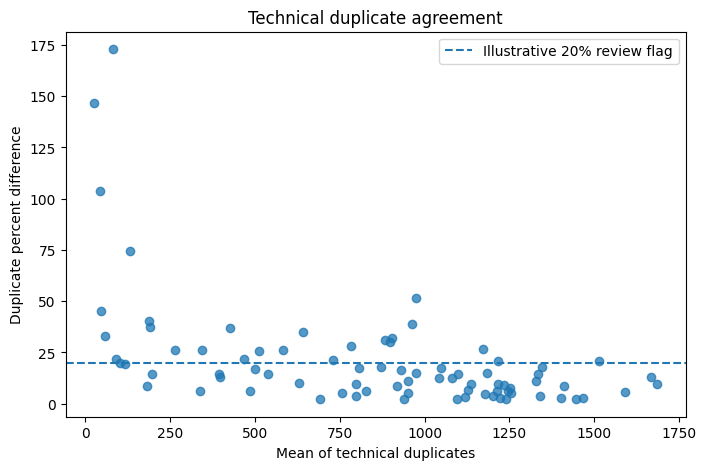

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    elisa["duplicate_mean"],
    elisa["duplicate_pct_difference"],
    alpha=0.75
)

ax.axhline(
    20,
    linestyle="--",
    linewidth=1.5,
    label="Illustrative 20% review flag"
)

ax.set_xlabel("Mean of technical duplicates")
ax.set_ylabel("Duplicate percent difference")
ax.set_title("Technical duplicate agreement")
ax.legend()

plt.show()


### Interpretation prompt

1. Are duplicate disagreements equally large across the concentration range?
2. Which samples would you review first?
3. What laboratory information would you want before excluding a flagged measurement?
4. Why would deleting every flagged point automatically be a poor analysis practice?

A defensible workflow separates:

- **flagging** a measurement;
- **investigating** the measurement;
- **excluding** the measurement.

Those are not the same action.


## 5. Verify the workbook calculations

The correction sheets calculate:

1. the mean of the two duplicates;
2. corrected corticosterone concentration.

From the formulas in the workbook, corrected concentration is:

$$
\text{corticosterone}
=
\text{duplicate mean}
\times
\frac{200}{1000}
$$

We can independently reproduce those calculations and compare them with the workbook values.


In [8]:
elisa["recalculated_average"] = elisa[
    ["duplicate_1", "duplicate_2"]
].mean(axis=1)

elisa["recalculated_cort_ng_ml"] = (
    elisa["recalculated_average"] *
    200 / 1000
)

elisa["average_difference"] = (
    elisa["recalculated_average"] -
    elisa["workbook_average"]
)

elisa["cort_difference"] = (
    elisa["recalculated_cort_ng_ml"] -
    elisa["workbook_cort_ng_ml"]
)

print(
    "Maximum absolute average discrepancy:",
    elisa["average_difference"].abs().max()
)

print(
    "Maximum absolute concentration discrepancy:",
    elisa["cort_difference"].abs().max()
)


Maximum absolute average discrepancy: 0.0
Maximum absolute concentration discrepancy: 0.0


Reproducing spreadsheet calculations is an important validation step.

For the remaining analysis, use the independently recalculated concentration:

`cort_ng_ml`


In [9]:
elisa["cort_ng_ml"] = (
    elisa["recalculated_cort_ng_ml"]
)


## 6. Add the biological metadata

The workbook's `Analysis` sheet identifies the animals as:

### SPS

1, 2, 3, 4, 11, 12, 15, 16, 17, 18, 19, 20

### Ether CON

5, 6, 7, 8, 9, 10, 13, 14

This biological metadata belongs at the **animal level**.

Each animal retains the same group assignment across all four time points.


In [10]:
sps_animals = [
    1, 2, 3, 4,
    11, 12,
    15, 16, 17, 18, 19, 20
]

ether_control_animals = [
    5, 6, 7, 8, 9, 10, 13, 14
]

group_lookup = {
    **{animal: "SPS" for animal in sps_animals},
    **{
        animal: "Ether CON"
        for animal in ether_control_animals
    }
}

elisa["group"] = elisa["animal"].map(group_lookup)

elisa["animal_id"] = (
    "A" +
    elisa["animal"].astype(str).str.zfill(2)
)

assert elisa["group"].notna().all()

elisa[
    ["animal_id", "group", "plate"]
].drop_duplicates().sort_values("animal_id")


,animal_id,group,plate
0,A01,SPS,1
4,A02,SPS,1
8,A03,SPS,1
12,A04,SPS,1
16,A05,Ether CON,1
20,A06,Ether CON,1
24,A07,Ether CON,1
28,A08,Ether CON,1
32,A09,Ether CON,1
36,A10,Ether CON,2


## 7. Verify the experimental design

Before choosing a statistical test, identify:

- the experimental unit;
- the between-subject factor;
- the within-subject factor;
- the outcome variable.

For this dataset:

- **experimental unit:** animal;
- **between-animal factor:** group (`SPS` vs `Ether CON`);
- **within-animal factor:** time (`30`, `60`, `120`, `180` minutes);
- **outcome:** corrected corticosterone concentration.

Technical duplicates do not increase the biological sample size.


In [11]:
design_summary = (
    elisa
    .groupby("group")
    .agg(
        animals=("animal_id", "nunique"),
        observations=("cort_ng_ml", "size")
    )
)

design_summary


,animals,observations
group,,
Ether CON,8,32
SPS,12,48


In [12]:
completeness = (
    elisa
    .pivot_table(
        index=["animal_id", "group"],
        columns="time_min",
        values="cort_ng_ml"
    )
)

completeness


,time_min,30,60,120,180
animal_id,group,,,,
A01,SPS,265.759,219.179,176.815,116.213
A02,SPS,333.463,235.633,93.604,17.899
A03,SPS,266.773,174.312,78.553,9.156
A04,SPS,250.816,216.004,96.935,20.132
A05,Ether CON,145.978,165.623,179.576,79.525
A06,Ether CON,183.477,243.388,223.623,67.391
A07,Ether CON,151.473,337.245,225.823,180.660
A08,Ether CON,209.451,246.488,192.281,107.689
A09,Ether CON,102.200,138.062,195.134,159.349


## 8. Start with the individual animals

A group mean can hide important biological variation.

The first scientific visualization should therefore show the repeated measurements for each animal.

Each line below represents one animal.


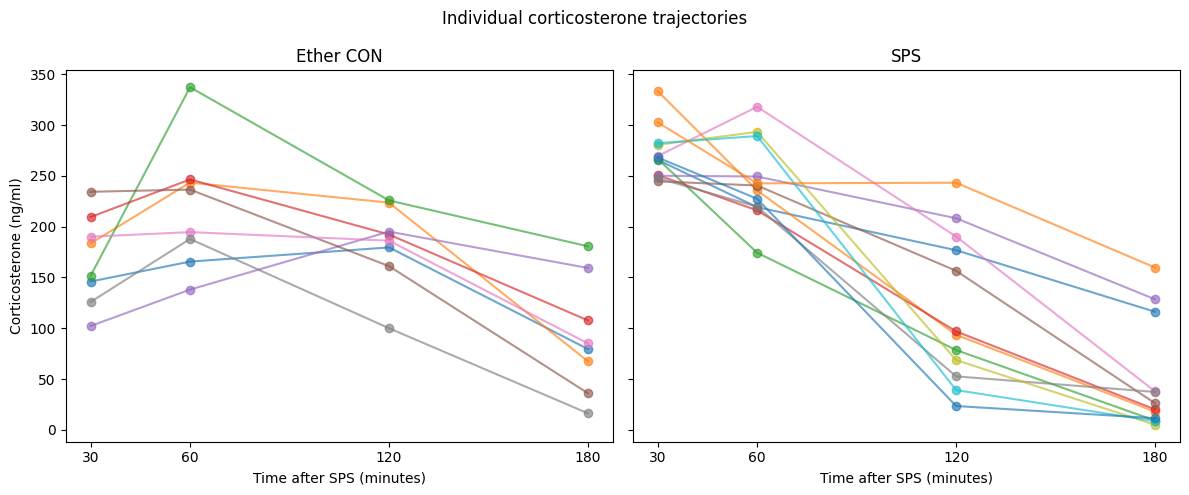

In [13]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5),
    sharey=True
)

for ax, group_name in zip(
    axes,
    ["Ether CON", "SPS"]
):

    subset = elisa[
        elisa["group"] == group_name
    ]

    for animal_id, animal_df in subset.groupby(
        "animal_id"
    ):
        animal_df = animal_df.sort_values(
            "time_min"
        )

        ax.plot(
            animal_df["time_min"],
            animal_df["cort_ng_ml"],
            marker="o",
            alpha=0.65
        )

    ax.set_title(group_name)
    ax.set_xlabel("Time after SPS (minutes)")
    ax.set_xticks([30, 60, 120, 180])

axes[0].set_ylabel(
    "Corticosterone (ng/ml)"
)

fig.suptitle(
    "Individual corticosterone trajectories"
)

plt.tight_layout()
plt.show()


### Questions before fitting a model

1. Does corticosterone appear to change linearly over time?
2. Do the two groups appear to have the same trajectory?
3. Is variability similar at every time point?
4. Are there animals whose trajectories look unusual?
5. Should time be treated as a continuous linear predictor or as a categorical repeated-measures factor?

With only four planned sampling times and an obviously non-linear biological trajectory, treating time as a **categorical factor** is a reasonable choice.


## 9. Summarize the group trajectories

For descriptive visualization, calculate the animal-level mean and standard error at each group × time combination.

The standard error is:

$$
SEM
=
\frac{s}{\sqrt{n}}
$$

where \(n\) is the number of animals, not the number of technical duplicate wells.


In [14]:
summary = (
    elisa
    .groupby(["group", "time_min"])["cort_ng_ml"]
    .agg(
        mean="mean",
        sd="std",
        n="count"
    )
    .reset_index()
)

summary["sem"] = (
    summary["sd"] /
    np.sqrt(summary["n"])
)

summary


,group,time_min,mean,sd,n,sem
0,Ether CON,30,167.862,44.260,8,15.648
1,Ether CON,60,218.728,61.643,8,21.794
2,Ether CON,120,182.982,39.823,8,14.080
3,Ether CON,180,91.499,56.464,8,19.963
4,SPS,30,271.852,25.663,12,7.408
5,SPS,60,243.772,39.520,12,11.409
6,SPS,120,119.023,72.888,12,21.041
7,SPS,180,48.160,54.134,12,15.627


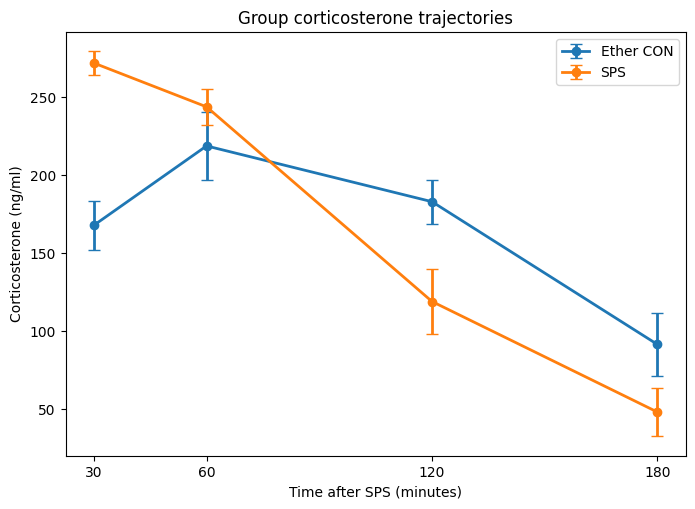

In [15]:
fig, ax = plt.subplots(
    figsize=(8, 5.5)
)

for group_name, group_df in summary.groupby(
    "group"
):
    group_df = group_df.sort_values(
        "time_min"
    )

    ax.errorbar(
        group_df["time_min"],
        group_df["mean"],
        yerr=group_df["sem"],
        marker="o",
        capsize=4,
        linewidth=2,
        label=group_name
    )

ax.set_xticks([30, 60, 120, 180])
ax.set_xlabel("Time after SPS (minutes)")
ax.set_ylabel("Corticosterone (ng/ml)")
ax.set_title("Group corticosterone trajectories")
ax.legend()

plt.show()


## 10. Why not perform four independent t-tests?

A separate test at 30, 60, 120, and 180 minutes would ignore the fact that measurements from the same animal are related.

The central scientific question is also not simply:

> Are the groups different at one isolated time point?

It is:

> **Does the pattern of corticosterone over time differ between the groups?**

That is a **group × time interaction** question.

A mixed-effects model can represent both:

- fixed effects of group and time;
- repeated observations within the same animal.


## 11. Mixed-effects model

We will fit:

$$
y_{ij}
=
\text{group}_i
+
\text{time}_j
+
(\text{group} \times \text{time})_{ij}
+
u_i
+
\epsilon_{ij}
$$

where:

- \(y_{ij}\) is corticosterone for animal \(i\) at time \(j\);
- \(u_i\) is an animal-specific random intercept;
- \(\epsilon_{ij}\) is residual variation.

In formula notation:

`cort_ng_ml ~ C(time_min) * C(group)`

with a random intercept for `animal_id`.

The 30-minute Ether CON group becomes the reference condition under the default coding.


In [16]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")

    full_model = smf.mixedlm(
        "cort_ng_ml ~ C(time_min) * C(group)",
        data=elisa,
        groups=elisa["animal_id"]
    ).fit(
        reml=False,
        method="powell",
        maxiter=1000,
        disp=False
    )

print(full_model.summary())


                       Mixed Linear Model Regression Results
Model:                     MixedLM          Dependent Variable:          cort_ng_ml
No. Observations:          80               Method:                      ML        
No. Groups:                20               Scale:                       1765.3372 
Min. group size:           4                Log-Likelihood:              -421.0959 
Max. group size:           4                Converged:                   Yes       
Mean group size:           4.0                                                     
-----------------------------------------------------------------------------------
                                    Coef.   Std.Err.   z    P>|z|  [0.025   0.975] 
-----------------------------------------------------------------------------------
Intercept                           167.862   17.177  9.772 0.000  134.195  201.528
C(time_min)[T.60]                    50.867   21.008  2.421 0.015    9.692   92.042
C(time_min)[T.1

### How to read the coefficients

Because 30 minutes and Ether CON are the reference categories:

- **Intercept** = estimated mean for Ether CON at 30 minutes.
- **`C(time_min)[T.60]`** = change from 30 to 60 minutes in Ether CON.
- **`C(group)[T.SPS]`** = SPS − Ether CON difference at 30 minutes.
- **interaction terms** = how much the SPS-versus-control group difference changes at later time points relative to 30 minutes.

The interaction coefficients are often the most important terms for the biological question.


## 12. Test the overall group × time interaction

Individual interaction coefficients compare each time point with the reference time.

To test the broader question

> **Does the time course differ between groups at all?**

compare:

### Full model

`time * group`

with:

### Reduced model

`time + group`

The reduced model assumes the two groups follow the same shape over time, apart from an overall group difference.

A likelihood-ratio test compares the two models.


In [17]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")

    reduced_model = smf.mixedlm(
        "cort_ng_ml ~ C(time_min) + C(group)",
        data=elisa,
        groups=elisa["animal_id"]
    ).fit(
        reml=False,
        method="powell",
        maxiter=1000,
        disp=False
    )

lr_stat = 2 * (
    full_model.llf -
    reduced_model.llf
)

df_difference = (
    len(full_model.fe_params) -
    len(reduced_model.fe_params)
)

interaction_p = stats.chi2.sf(
    lr_stat,
    df_difference
)

print(
    f"Likelihood-ratio statistic: "
    f"{lr_stat:.3f}"
)

print(
    f"Degrees of freedom: "
    f"{df_difference}"
)

print(
    f"Overall group × time p-value: "
    f"{interaction_p:.5g}"
)


Likelihood-ratio statistic: 34.719
Degrees of freedom: 3
Overall group × time p-value: 1.3967e-07


### Interpretation

If the group × time interaction is supported, the meaning is:

> The difference between SPS and Ether CON is not constant across time.

That motivates time-specific follow-up comparisons.

The interaction is usually more informative than reporting one overall group main effect when the trajectories clearly change over time.


## 13. Model-based group comparisons at each time point

The fitted model expresses all effects relative to the reference categories.

To recover the SPS − Ether CON difference at each time:

### 30 minutes

$$
\beta_{\mathrm{SPS}}
$$

### 60 minutes

$$
\beta_{\mathrm{SPS}}
+
\beta_{\mathrm{60:SPS}}
$$

and similarly for 120 and 180 minutes.

Because four follow-up comparisons are being examined, we will also report Holm-adjusted p-values.


In [18]:
parameter_names = list(
    full_model.fe_params.index
)

contrast_rows = []

for time_min in [30, 60, 120, 180]:

    contrast = np.zeros(
        len(parameter_names)
    )

    contrast[
        parameter_names.index(
            "C(group)[T.SPS]"
        )
    ] = 1

    if time_min != 30:
        interaction_name = (
            f"C(time_min)[T.{time_min}]"
            ":C(group)[T.SPS]"
        )

        contrast[
            parameter_names.index(
                interaction_name
            )
        ] = 1

    result = full_model.t_test(
        contrast.reshape(1, -1)
    )

    ci = result.conf_int()[0]

    contrast_rows.append({
        "time_min": time_min,
        "SPS_minus_EtherCON": float(
            result.effect[0]
        ),
        "SE": float(result.sd[0, 0]),
        "CI_low": float(ci[0]),
        "CI_high": float(ci[1]),
        "p_value": float(
            np.asarray(result.pvalue).squeeze()
        )
    })

contrasts = pd.DataFrame(
    contrast_rows
)

contrasts["p_holm"] = multipletests(
    contrasts["p_value"],
    method="holm"
)[1]

contrasts


,time_min,SPS_minus_EtherCON,SE,CI_low,CI_high,p_value,p_holm
0,30,103.991,22.175,60.528,147.454,2.739e-06,1.096e-05
1,60,25.043,22.175,-18.419,68.506,2.588e-01,2.588e-01
2,120,-63.959,22.175,-107.422,-20.496,3.924e-03,1.177e-02
3,180,-43.338,22.175,-86.801,0.125,5.066e-02,1.013e-01


## 14. Check model diagnostics

Statistical models make assumptions about the unexplained variation.

At minimum, inspect:

1. residuals versus fitted values;
2. residual distribution / Q-Q plot;
3. whether extreme observations dominate the conclusions.

A diagnostic plot does not provide a binary "pass/fail" decision. It helps identify patterns that may require a different model, transformation, or sensitivity analysis.


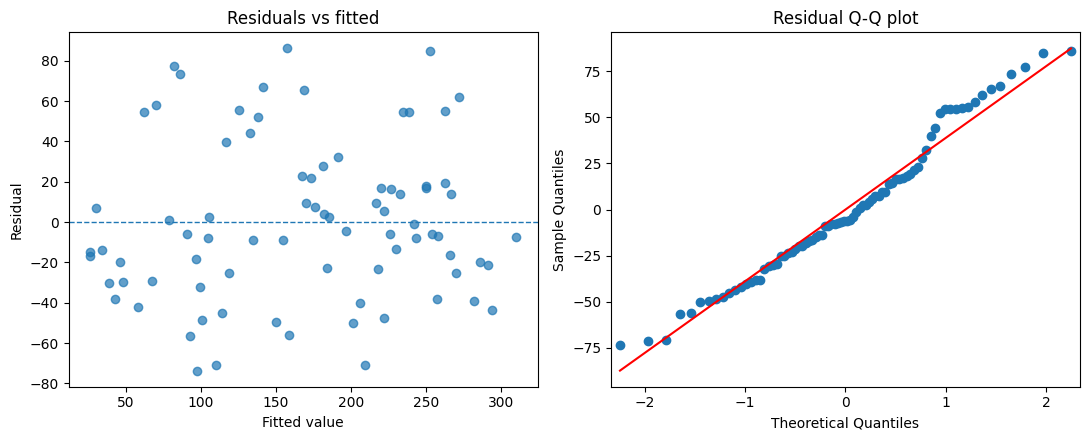

In [19]:
diagnostics = elisa.copy()

diagnostics["fitted"] = full_model.fittedvalues
diagnostics["residual"] = full_model.resid

fig, axes = plt.subplots(
    1, 2,
    figsize=(11, 4.5)
)

# Residuals vs fitted
axes[0].scatter(
    diagnostics["fitted"],
    diagnostics["residual"],
    alpha=0.7
)

axes[0].axhline(
    0,
    linestyle="--",
    linewidth=1
)

axes[0].set_xlabel("Fitted value")
axes[0].set_ylabel("Residual")
axes[0].set_title("Residuals vs fitted")


# Correct Q-Q plot
sm.qqplot(
    diagnostics["residual"],
    line="s",
    ax=axes[1]
)

axes[1].set_title("Residual Q-Q plot")

plt.tight_layout()
plt.show()

In [20]:
# ------------------------------------------------------------
# Simulation-based predictive check for the mixed-effects model
# ------------------------------------------------------------

rng = np.random.default_rng(42)

n_simulations = 1000

# Fixed-effect prediction for every observation
fixed_prediction = (
    full_model.model.exog
    @ full_model.fe_params.to_numpy()
)

# Estimated variance components
animal_sd = np.sqrt(
    float(full_model.cov_re.iloc[0, 0])
)

residual_sd = np.sqrt(
    float(full_model.scale)
)

# Map animal IDs to integer indices
animal_codes, animal_levels = pd.factorize(
    elisa["animal_id"],
    sort=True
)

n_animals = len(animal_levels)

# Store simulated datasets
simulated_data = np.zeros(
    (
        n_simulations,
        len(elisa)
    )
)

for sim in range(n_simulations):

    # Simulate one random intercept for each animal
    simulated_animal_effects = rng.normal(
        loc=0,
        scale=animal_sd,
        size=n_animals
    )

    # Simulate residual error
    simulated_residuals = rng.normal(
        loc=0,
        scale=residual_sd,
        size=len(elisa)
    )

    # Generate a replicated dataset
    simulated_data[sim] = (
        fixed_prediction
        + simulated_animal_effects[animal_codes]
        + simulated_residuals
    )

In [21]:
predictive_rows = []

for group_name in [
    "Ether CON",
    "SPS"
]:

    for time_min in [
        30,
        60,
        120,
        180
    ]:

        mask = (
            (elisa["group"] == group_name)
            &
            (elisa["time_min"] == time_min)
        ).to_numpy()

        # All simulated observations belonging to this cell
        simulated_values = simulated_data[
            :,
            mask
        ].reshape(-1)

        # Model's fixed-effect mean for this cell
        predicted_mean = fixed_prediction[
            mask
        ].mean()

        predictive_rows.append({
            "group": group_name,
            "time_min": time_min,
            "predicted_mean": predicted_mean,
            "predictive_low": np.quantile(
                simulated_values,
                0.025
            ),
            "predictive_high": np.quantile(
                simulated_values,
                0.975
            )
        })

predictive_summary = pd.DataFrame(
    predictive_rows
)

predictive_summary

,group,time_min,predicted_mean,predictive_low,predictive_high
0,Ether CON,30,167.862,73.460,261.446
1,Ether CON,60,218.728,123.484,316.011
2,Ether CON,120,182.982,88.580,277.753
3,Ether CON,180,91.499,-9.244,185.653
4,SPS,30,271.852,176.407,367.656
5,SPS,60,243.772,147.795,339.098
6,SPS,120,119.023,21.994,214.370
7,SPS,180,48.160,-48.350,144.011


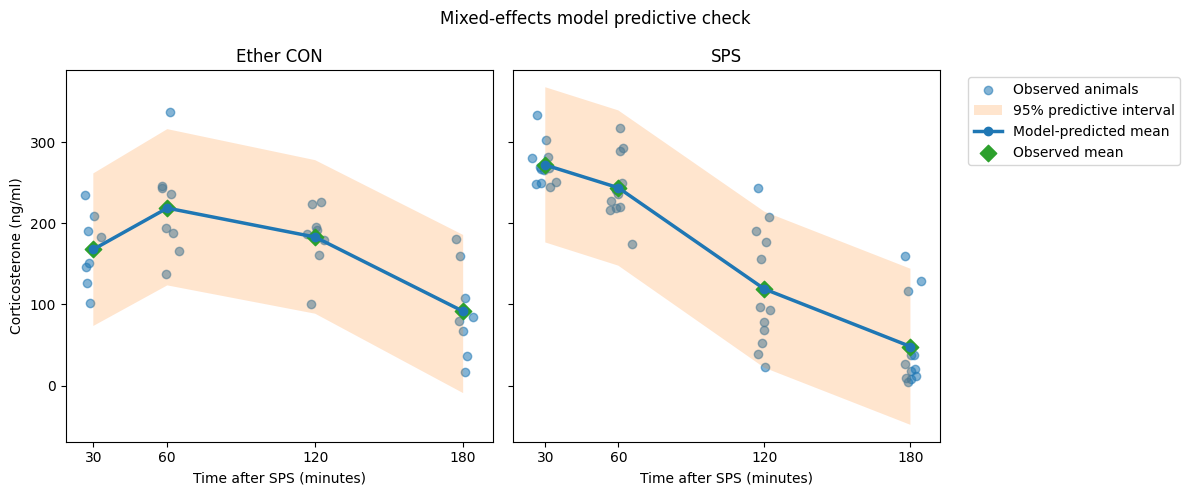

In [22]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 5),
    sharey=True
)

for ax, group_name in zip(
    axes,
    ["Ether CON", "SPS"]
):

    observed_group = elisa[
        elisa["group"] == group_name
    ]

    predicted_group = predictive_summary[
        predictive_summary["group"]
        == group_name
    ].sort_values("time_min")

    # Slight horizontal jitter so individual animals are visible
    jitter = rng.normal(
        0,
        2.0,
        size=len(observed_group)
    )

    # Empirical observations
    ax.scatter(
        observed_group["time_min"] + jitter,
        observed_group["cort_ng_ml"],
        alpha=0.55,
        label="Observed animals"
    )

    # Predictive interval
    ax.fill_between(
        predicted_group["time_min"],
        predicted_group["predictive_low"],
        predicted_group["predictive_high"],
        alpha=0.2,
        label="95% predictive interval"
    )

    # Model-predicted mean
    ax.plot(
        predicted_group["time_min"],
        predicted_group["predicted_mean"],
        marker="o",
        linewidth=2.5,
        label="Model-predicted mean"
    )

    # Observed group means
    observed_means = (
        observed_group
        .groupby("time_min")["cort_ng_ml"]
        .mean()
    )

    ax.scatter(
        observed_means.index,
        observed_means.values,
        marker="D",
        s=70,
        label="Observed mean"
    )

    ax.set_title(group_name)

    ax.set_xlabel(
        "Time after SPS (minutes)"
    )

    ax.set_xticks(
        [30, 60, 120, 180]
    )

axes[0].set_ylabel(
    "Corticosterone (ng/ml)"
)

axes[1].legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.suptitle(
    "Mixed-effects model predictive check"
)

plt.tight_layout()
plt.show()

### What are you looking for?

In the residual-versus-fitted plot:

- a strong curve may indicate model misspecification;
- a funnel shape may indicate changing residual variance;
- isolated extreme points deserve investigation.

In the Q-Q plot:

- large systematic departures from the diagonal suggest the residual distribution differs substantially from normality.

Do not remove an observation simply because its residual is large. First return to the raw measurement and laboratory context.


## 15. Quantify the Gaussian mixed-model fit

Residual plots are essential, but it is also useful to summarize how closely the fitted model reproduces the observed values.

We will calculate:

- **RMSE**: typical prediction error, with larger errors weighted more heavily;
- **MAE**: typical absolute prediction error;
- **marginal \(R^2\)**: variance explained by the fixed effects;
- **conditional \(R^2\)**: variance explained by the fixed effects plus the animal-level random intercept.

For a random-intercept model, an approximate variance decomposition is

$$
R^2_{\mathrm{marginal}}
=
\frac{\sigma^2_{\mathrm{fixed}}}
{\sigma^2_{\mathrm{fixed}}
+
\sigma^2_{\mathrm{animal}}
+
\sigma^2_{\mathrm{residual}}}
$$

and

$$
R^2_{\mathrm{conditional}}
=
\frac{
\sigma^2_{\mathrm{fixed}}
+
\sigma^2_{\mathrm{animal}}
}
{
\sigma^2_{\mathrm{fixed}}
+
\sigma^2_{\mathrm{animal}}
+
\sigma^2_{\mathrm{residual}}
}.
$$

These are descriptive measures of fit. They do not replace model diagnostics.


In [23]:
observed = elisa["cort_ng_ml"].to_numpy()

# Predictions including the fitted animal-specific random intercept.
conditional_fitted = np.asarray(
    full_model.fittedvalues
)

# Predictions using fixed effects only.
fixed_fitted = (
    full_model.model.exog
    @ full_model.fe_params.to_numpy()
)

mixed_rmse = np.sqrt(
    np.mean(
        (observed - conditional_fitted) ** 2
    )
)

mixed_mae = np.mean(
    np.abs(
        observed - conditional_fitted
    )
)

var_fixed = np.var(
    fixed_fitted,
    ddof=1
)

var_animal = float(
    full_model.cov_re.iloc[0, 0]
)

var_residual = float(
    full_model.scale
)

total_variance = (
    var_fixed
    + var_animal
    + var_residual
)

marginal_r2 = (
    var_fixed /
    total_variance
)

conditional_r2 = (
    (var_fixed + var_animal) /
    total_variance
)

fit_metrics = pd.DataFrame({
    "metric": [
        "RMSE",
        "MAE",
        "Marginal R²",
        "Conditional R²",
        "Animal random-intercept SD",
        "Residual SD"
    ],
    "value": [
        mixed_rmse,
        mixed_mae,
        marginal_r2,
        conditional_r2,
        np.sqrt(var_animal),
        np.sqrt(var_residual)
    ]
})

fit_metrics


,metric,value
0,RMSE,38.884
1,MAE,31.371
2,Marginal R²,0.715
3,Conditional R²,0.787
4,Animal random-intercept SD,24.394
5,Residual SD,42.016


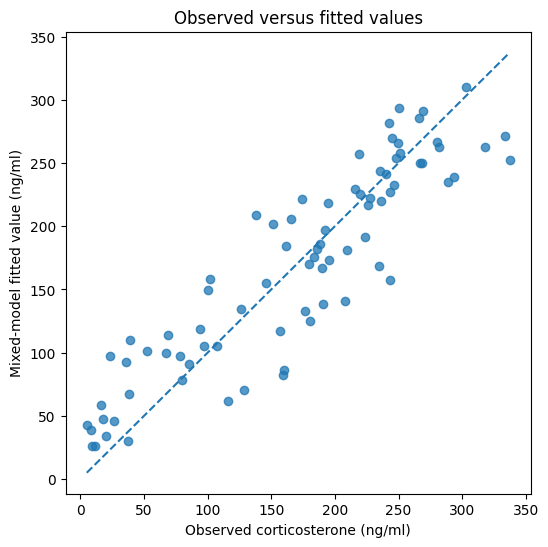

In [24]:
fig, ax = plt.subplots(
    figsize=(6, 6)
)

ax.scatter(
    observed,
    conditional_fitted,
    alpha=0.75
)

low = min(
    observed.min(),
    conditional_fitted.min()
)

high = max(
    observed.max(),
    conditional_fitted.max()
)

ax.plot(
    [low, high],
    [low, high],
    linestyle="--",
    linewidth=1.5
)

ax.set_xlabel(
    "Observed corticosterone (ng/ml)"
)

ax.set_ylabel(
    "Mixed-model fitted value (ng/ml)"
)

ax.set_title(
    "Observed versus fitted values"
)

plt.show()


### Smooth predictive-density check for the Gaussian mixed model

The trajectory plot above checks predictions across time. We can also ask whether the fitted model reproduces the **overall distribution** of corticosterone values.

To make this comparable with the Bayesian posterior predictive check later, we condition on the fitted animal-specific random effects and repeatedly simulate new residual error:

$$
y_{ij}^{rep}
=
\hat{y}_{ij}
+
\epsilon_{ij}^{rep},
\qquad
\epsilon_{ij}^{rep}
\sim
\mathrm{Normal}
\left(
0,
\hat{\sigma}_{residual}
\right).
$$

The empirical density is compared with smooth densities from many model-generated datasets.

This is a **simulation-based predictive check**, not a posterior predictive check, because the frequentist model does not contain a posterior distribution over its parameters.


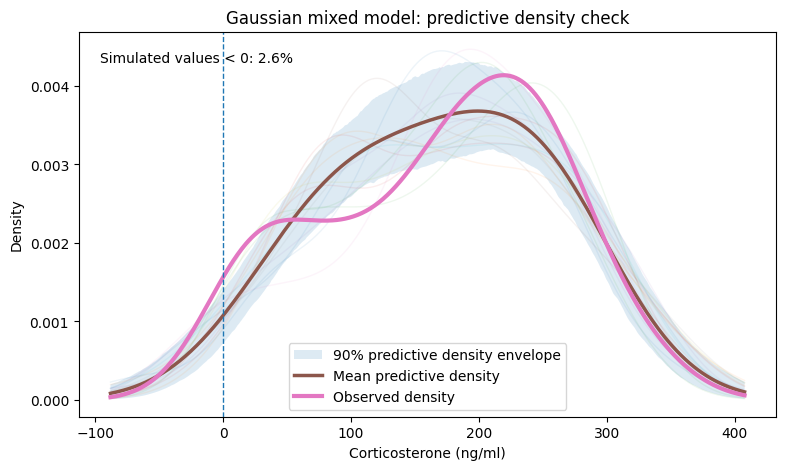

In [25]:
from scipy.stats import gaussian_kde

rng_density = np.random.default_rng(
    42
)

n_density_replicates = 500

# Conditional fitted values include the fitted random intercept
# for each observed animal.
gaussian_replicates = (
    conditional_fitted[None, :]
    +
    rng_density.normal(
        loc=0,
        scale=np.sqrt(
            var_residual
        ),
        size=(
            n_density_replicates,
            len(observed)
        )
    )
)

gaussian_negative_fraction = np.mean(
    gaussian_replicates < 0
)

plot_low = min(
    observed.min(),
    np.quantile(
        gaussian_replicates,
        0.001
    )
)

plot_high = max(
    observed.max(),
    np.quantile(
        gaussian_replicates,
        0.999
    )
)

padding = 0.05 * (
    plot_high -
    plot_low
)

x_grid_gaussian = np.linspace(
    plot_low - padding,
    plot_high + padding,
    450
)

observed_density_gaussian = gaussian_kde(
    observed
)(
    x_grid_gaussian
)

gaussian_density_matrix = np.asarray([
    gaussian_kde(
        replicate
    )(
        x_grid_gaussian
    )
    for replicate in gaussian_replicates
])

gaussian_density_low = np.quantile(
    gaussian_density_matrix,
    0.05,
    axis=0
)

gaussian_density_high = np.quantile(
    gaussian_density_matrix,
    0.95,
    axis=0
)

fig, ax = plt.subplots(
    figsize=(
        9,
        5
    )
)

# A small number of individual replicated densities.
curve_ids = rng_density.choice(
    n_density_replicates,
    size=15,
    replace=False
)

for curve_id in curve_ids:
    ax.plot(
        x_grid_gaussian,
        gaussian_density_matrix[
            curve_id
        ],
        alpha=0.08,
        linewidth=1
    )

ax.fill_between(
    x_grid_gaussian,
    gaussian_density_low,
    gaussian_density_high,
    alpha=0.15,
    label="90% predictive density envelope"
)

ax.plot(
    x_grid_gaussian,
    gaussian_density_matrix.mean(
        axis=0
    ),
    linewidth=2.5,
    label="Mean predictive density"
)

ax.plot(
    x_grid_gaussian,
    observed_density_gaussian,
    linewidth=3,
    label="Observed density"
)

ax.axvline(
    0,
    linestyle="--",
    linewidth=1
)

ax.text(
    0.03,
    0.95,
    (
        "Simulated values < 0: "
        f"{gaussian_negative_fraction:.1%}"
    ),
    transform=ax.transAxes,
    va="top"
)

ax.set_xlabel(
    "Corticosterone (ng/ml)"
)

ax.set_ylabel(
    "Density"
)

ax.set_title(
    "Gaussian mixed model: predictive density check"
)

ax.legend()

plt.show()


The vertical line at zero marks the lower biological boundary for a concentration measurement.

If the Gaussian model assigns noticeable probability below zero, that does not automatically invalidate its estimate of the mean trajectory. It does show that the observation model is generating some biologically impossible values.

This provides one concrete reason to consider a positive-valued likelihood.


### A limitation of the Gaussian mixed model

The model above makes one strong assumption that is easy to overlook:

> after accounting for group, time, and animal, the residual standard deviation is the **same for every observation**.

The data do not necessarily have the same amount of variability at every group × time combination.

Examine the observed standard deviations:


In [26]:
cell_variability = (
    elisa
    .groupby(
        ["group", "time_min"]
    )["cort_ng_ml"]
    .agg(
        mean="mean",
        sd="std",
        n="count"
    )
    .reset_index()
)

cell_variability["coefficient_of_variation"] = (
    cell_variability["sd"] /
    cell_variability["mean"]
)

cell_variability


,group,time_min,mean,sd,n,coefficient_of_variation
0,Ether CON,30,167.862,44.260,8,0.264
1,Ether CON,60,218.728,61.643,8,0.282
2,Ether CON,120,182.982,39.823,8,0.218
3,Ether CON,180,91.499,56.464,8,0.617
4,SPS,30,271.852,25.663,12,0.094
5,SPS,60,243.772,39.520,12,0.162
6,SPS,120,119.023,72.888,12,0.612
7,SPS,180,48.160,54.134,12,1.124


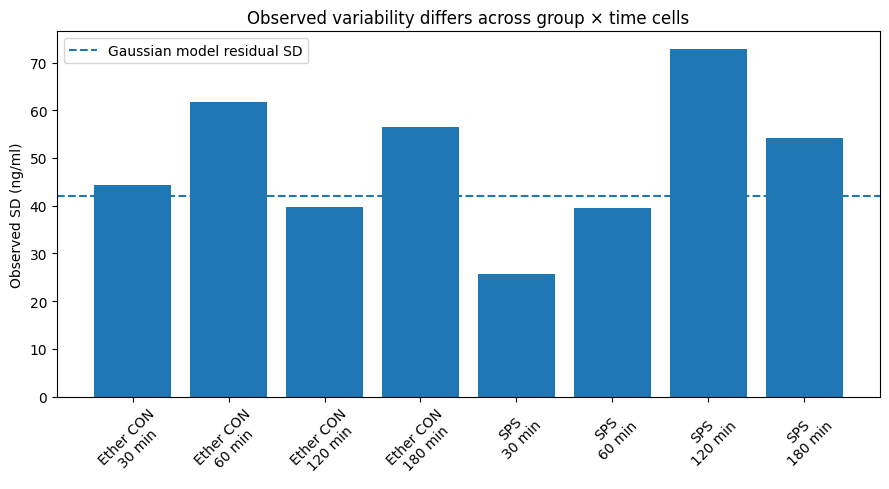

In [27]:
fig, ax = plt.subplots(
    figsize=(9, 5)
)

labels = (
    cell_variability["group"]
    + "\n"
    + cell_variability["time_min"].astype(str)
    + " min"
)

ax.bar(
    labels,
    cell_variability["sd"]
)

ax.axhline(
    np.sqrt(var_residual),
    linestyle="--",
    linewidth=1.5,
    label="Gaussian model residual SD"
)

ax.set_ylabel(
    "Observed SD (ng/ml)"
)

ax.set_title(
    "Observed variability differs across group × time cells"
)

ax.tick_params(
    axis="x",
    rotation=45
)

ax.legend()

plt.tight_layout()
plt.show()


### Is the frequentist model "bad"?

Not necessarily.

The Gaussian mixed model may still provide a useful summary of the mean trajectory. Its residual diagnostics should determine whether the approximation is acceptable.

However, the model has structural limitations:

1. corticosterone concentration cannot be negative;
2. the Gaussian likelihood allows negative values;
3. biological concentration data can be right-skewed;
4. the Gaussian model uses one residual variance for all group × time cells.

A more flexible model can address those assumptions directly.

The next model is **Bayesian**, but Bayesian inference itself is not what improves model fit.

The improvement comes from specifying a different **data-generating model**.


# 16. Bayesian hierarchical Gamma alternative

The Gaussian mixed model captures the repeated-measures mean structure reasonably well, but the predictive checks raise two additional questions:

1. should a concentration model be allowed to generate negative values?
2. should every group × time cell be forced to have the same residual variability?

A Gamma likelihood addresses the first issue because it is defined only for positive values.

The data also show substantial differences in relative variability across group × time cells. A single residual variance can therefore be too restrictive.

However, estimating eight completely independent variance parameters can be unstable with a modest number of animals.

The compromise is a **hierarchical variance model**:

- each group × time cell receives its own coefficient of variation;
- those eight coefficients of variation are partially pooled toward a common distribution;
- cells with less information borrow strength from the others.

The mean model is:

$$
\log(\mu_{ij})
=
\beta_0
+
\mathbf{x}_{ij}^{T}\boldsymbol{\beta}
+
u_i,
$$

with

$$
u_i
\sim
\mathrm{Normal}
\left(
0,
\sigma_{\mathrm{animal}}
\right).
$$

The observation model is:

$$
y_{ij}
\sim
\mathrm{Gamma}
\left(
\mu=\mu_{ij},
\sigma=\mu_{ij}CV_{g,t}
\right).
$$

The cell-specific coefficients of variation are modeled hierarchically:

$$
\log(CV_k)
=
\mu_{CV}
+
\sigma_{CV}z_k,
\qquad
z_k
\sim
\mathrm{Normal}(0,1).
$$

This keeps the flexibility that helped the Gamma model reproduce the empirical distribution while regularizing the cell-specific variance estimates.


## 16.1 Import the Bayesian modeling packages

### macOS / Apple Silicon note

Some recent macOS toolchains can cause PyTensor C-linker errors such as:

`ld: library 'd64' not found`

For this small classroom dataset, the simplest workaround is to disable PyTensor's optional C++ compilation.

**Run this cell before importing PyMC or PyTensor in a fresh kernel.**


In [28]:
import os

os.environ.setdefault(
    "PYTENSOR_FLAGS",
    "cxx="
)

import pymc as pm
import arviz as az
import pytensor
import patsy

print(
    "PyMC:",
    pm.__version__
)

print(
    "PyTensor:",
    pytensor.__version__
)

print(
    "ArviZ:",
    az.__version__
)

print(
    "PyTensor C++ compiler:",
    repr(
        pytensor.config.cxx
    )
)


/opt/homebrew/Caskroom/miniforge/base/envs/rose_gnn/lib/python3.10/site-packages/arviz/__init__.py:50: FutureWarning: 
ArviZ is undergoing a major refactor to improve flexibility and extensibility while maintaining a user-friendly interface.
Some upcoming changes may be backward incompatible.
For details and migration guidance, visit: https://python.arviz.org/en/latest/user_guide/migration_guide.html
  warn(


PyMC: 5.25.1
PyTensor: 2.31.7
ArviZ: 0.23.4
PyTensor C++ compiler: ''


## 16.2 Build the model matrix

The Bayesian model answers the same scientific question as the frequentist mixed model.

The reference categories remain:

- 30 minutes;
- Ether CON.

The model therefore retains the same group, categorical-time, and group × time structure.


In [29]:
design = patsy.dmatrix(
    (
        "C(time_min, Treatment(reference=30))"
        " * "
        "C(group, Treatment(reference='Ether CON'))"
    ),
    data=elisa,
    return_type="dataframe"
)

coefficient_names = list(
    design.columns[1:]
)

X_bayes = (
    design
    .iloc[:, 1:]
    .to_numpy()
)

animal_codes, animal_levels = pd.factorize(
    elisa["animal_id"],
    sort=True
)

cell_labels = (
    elisa["group"]
    + " | "
    + elisa["time_min"].astype(str)
    + " min"
)

cell_codes, cell_levels = pd.factorize(
    cell_labels,
    sort=True
)

print(
    "Fixed-effect coefficients:"
)

for name in coefficient_names:
    print(
        " -",
        name
    )

print(
    "\nVariance cells:"
)

for name in cell_levels:
    print(
        " -",
        name
    )


Fixed-effect coefficients:
 - C(time_min, Treatment(reference=30))[T.60]
 - C(time_min, Treatment(reference=30))[T.120]
 - C(time_min, Treatment(reference=30))[T.180]
 - C(group, Treatment(reference='Ether CON'))[T.SPS]
 - C(time_min, Treatment(reference=30))[T.60]:C(group, Treatment(reference='Ether CON'))[T.SPS]
 - C(time_min, Treatment(reference=30))[T.120]:C(group, Treatment(reference='Ether CON'))[T.SPS]
 - C(time_min, Treatment(reference=30))[T.180]:C(group, Treatment(reference='Ether CON'))[T.SPS]

Variance cells:
 - Ether CON | 120 min
 - Ether CON | 180 min
 - Ether CON | 30 min
 - Ether CON | 60 min
 - SPS | 120 min
 - SPS | 180 min
 - SPS | 30 min
 - SPS | 60 min


## 16.3 Specify the hierarchical Gamma model

The animal random effects and the cell-specific variability effects are both written in non-centered form.

This is useful in hierarchical models because it often gives the sampler easier posterior geometry.

The model has two different types of partial pooling:

1. **animal-level pooling** for baseline differences among animals;
2. **variance-level pooling** for the eight group × time coefficients of variation.


In [30]:
coords = {
    "observation": np.arange(
        len(elisa)
    ),
    "animal": list(
        animal_levels
    ),
    "coefficient": coefficient_names,
    "variance_cell": list(
        cell_levels
    )
}

with pm.Model(
    coords=coords
) as bayes_model:

    X_data = pm.Data(
        "X_data",
        X_bayes,
        dims=(
            "observation",
            "coefficient"
        )
    )

    animal_idx = pm.Data(
        "animal_idx",
        animal_codes,
        dims="observation"
    )

    variance_cell_idx = pm.Data(
        "variance_cell_idx",
        cell_codes,
        dims="observation"
    )

    # -------------------------
    # Mean structure
    # -------------------------

    intercept = pm.Normal(
        "intercept",
        mu=np.log(
            np.median(
                elisa[
                    "cort_ng_ml"
                ]
            )
        ),
        sigma=0.75
    )

    beta = pm.Normal(
        "beta",
        mu=0,
        sigma=0.75,
        dims="coefficient"
    )

    # -------------------------
    # Animal-level hierarchy
    # -------------------------

    animal_sd = pm.HalfNormal(
        "animal_sd",
        sigma=0.3
    )

    animal_z = pm.Normal(
        "animal_z",
        mu=0,
        sigma=1,
        dims="animal"
    )

    animal_offset = pm.Deterministic(
        "animal_offset",
        animal_z * animal_sd,
        dims="animal"
    )

    eta = (
        intercept
        + pm.math.dot(
            X_data,
            beta
        )
        + animal_offset[
            animal_idx
        ]
    )

    expected_cort = pm.Deterministic(
        "expected_cort",
        pm.math.exp(
            eta
        ),
        dims="observation"
    )

    # -------------------------
    # Hierarchical CV model
    # -------------------------

    log_cv_mean = pm.Normal(
        "log_cv_mean",
        mu=np.log(
            0.3
        ),
        sigma=0.75
    )

    log_cv_sd = pm.HalfNormal(
        "log_cv_sd",
        sigma=0.75
    )

    cv_z = pm.Normal(
        "cv_z",
        mu=0,
        sigma=1,
        dims="variance_cell"
    )

    log_cell_cv = pm.Deterministic(
        "log_cell_cv",
        (
            log_cv_mean
            + log_cv_sd * cv_z
        ),
        dims="variance_cell"
    )

    cell_cv = pm.Deterministic(
        "cell_cv",
        pm.math.exp(
            log_cell_cv
        ),
        dims="variance_cell"
    )

    observation_sd = (
        expected_cort
        * cell_cv[
            variance_cell_idx
        ]
    )

    cort_obs = pm.Gamma(
        "cort_obs",
        mu=expected_cort,
        sigma=observation_sd,
        observed=elisa[
            "cort_ng_ml"
        ].to_numpy(),
        dims="observation"
    )


## 16.4 Sample from the posterior

A higher `target_accept` is used because hierarchical variance models can have challenging posterior geometry.

Two chains are used here because disabling PyTensor C compilation can make sampling quite slow on some Macs.

For final publication-quality convergence assessment, four chains are preferable when computationally feasible.


In [31]:
with bayes_model:

    idata = pm.sample(
        draws=1000,
        tune=2000,
        chains=2,
        cores=2,
        target_accept=0.99,
        random_seed=42,
        return_inferencedata=True
    )


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (2 chains in 2 jobs)
NUTS: [intercept, beta, animal_sd, animal_z, log_cv_mean, log_cv_sd, cv_z]
/opt/homebrew/Caskroom/miniforge/base/envs/rose_gnn/lib/python3.10/site-packages/pytensor/scalar/basic.py:3191: RuntimeWarning: overflow encountered in exp
  return np.exp(x)
/opt/homebrew/Caskroom/miniforge/base/envs/rose_gnn/lib/python3.10/site-packages/pytensor/scalar/basic.py:2094: RuntimeWarning: invalid value encountered in divide
  return x / y


/opt/homebrew/Caskroom/miniforge/base/envs/rose_gnn/lib/python3.10/site-packages/rich/live.py:260: UserWarning: 
install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

/opt/homebrew/Caskroom/miniforge/base/envs/rose_gnn/lib/python3.10/site-packages/numpy/core/fromnumeric.py:88: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)
/opt/homebrew/Caskroom/miniforge/base/envs/rose_gnn/lib/python3.10/site-packages/pytensor/scalar/basic.py:2981: RuntimeWarning: divide by zero encountered in scalar divide
  return np.float32(1.0) / x
/opt/homebrew/Caskroom/miniforge/base/envs/rose_gnn/lib/python3.10/site-packages/pytensor/scalar/basic.py:3297: RuntimeWarning: overflow encountered in scalar multiply
  return x * x
/opt/homebrew/Caskroom/miniforge/base/envs/rose_gnn/lib/python3.10/site-packages/numpy/core/fromnumeric.py:88: RuntimeWarning: invalid value encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)
/opt/homebrew/Caskroom/miniforge/base/envs/rose_gnn/lib/python3.10/site-packages/pytensor/scalar/basic.py:3023: RuntimeWarning: divide by zero encountered in log
  return np.log

Sampling 2 chains for 2_000 tune and 215 draw iterations (4_000 + 430 draws total) took 3987 seconds.
We recommend running at least 4 chains for robust computation of convergence diagnostics
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details


## 16.5 Check sampling diagnostics before interpreting the model

Sampling completion does not guarantee a trustworthy posterior.

Check:

- divergences;
- R-hat;
- effective sample size;
- trace plots.

A practical target is:

- zero divergences if possible;
- R-hat close to 1 and ideally below about 1.01;
- adequate effective sample size.

If the sampler still produces substantial divergences, the model should be reparameterized or further regularized before drawing scientific conclusions.


In [32]:
bayes_parameter_summary = az.summary(
    idata,
    var_names=[
        "intercept",
        "beta",
        "animal_sd",
        "log_cv_mean",
        "log_cv_sd",
        "cell_cv"
    ],
    round_to=3
)

diagnostic_table = bayes_parameter_summary[
    [
        "mean",
        "sd",
        "hdi_3%",
        "hdi_97%",
        "ess_bulk",
        "r_hat"
    ]
]

diagnostic_table


,mean,sd,hdi_3%,hdi_97%,ess_bulk,r_hat
intercept,5.159,0.096,4.995,5.343,158.338,1.005
"beta[C(time_min, Treatment(reference=30))[T.60]]",0.222,0.130,0.005,0.486,190.111,1.021
"beta[C(time_min, Treatment(reference=30))[T.120]]",0.048,0.128,-0.176,0.298,309.831,1.006
"beta[C(time_min, Treatment(reference=30))[T.180]]",-0.647,0.252,-1.026,-0.086,393.671,1.005
"beta[C(group, Treatment(reference='Ether CON'))[T.SPS]]",0.443,0.101,0.249,0.608,182.748,1.001
"beta[C(time_min, Treatment(reference=30))[T.60]:C(group, Treatment(reference='Ether CON'))[T.SPS]]",-0.328,0.144,-0.569,-0.033,188.638,1.007
"beta[C(time_min, Treatment(reference=30))[T.120]:C(group, Treatment(reference='Ether CON'))[T.SPS]]",-0.810,0.242,-1.257,-0.330,438.256,0.997
"beta[C(time_min, Treatment(reference=30))[T.180]:C(group, Treatment(reference='Ether CON'))[T.SPS]]",-0.863,0.374,-1.564,-0.233,233.268,1.011
animal_sd,0.083,0.039,0.005,0.145,99.654,1.041
log_cv_mean,-1.157,0.311,-1.736,-0.537,88.759,1.014


In [33]:
n_divergences = int(
    idata
    .sample_stats[
        "diverging"
    ]
    .sum()
)

max_rhat = float(
    diagnostic_table[
        "r_hat"
    ].max()
)

min_ess = float(
    diagnostic_table[
        "ess_bulk"
    ].min()
)

print(
    "Divergences:",
    n_divergences
)

print(
    "Maximum R-hat:",
    round(
        max_rhat,
        4
    )
)

print(
    "Minimum bulk ESS:",
    round(
        min_ess,
        1
    )
)


Divergences: 0
Maximum R-hat: 1.041
Minimum bulk ESS: 88.8


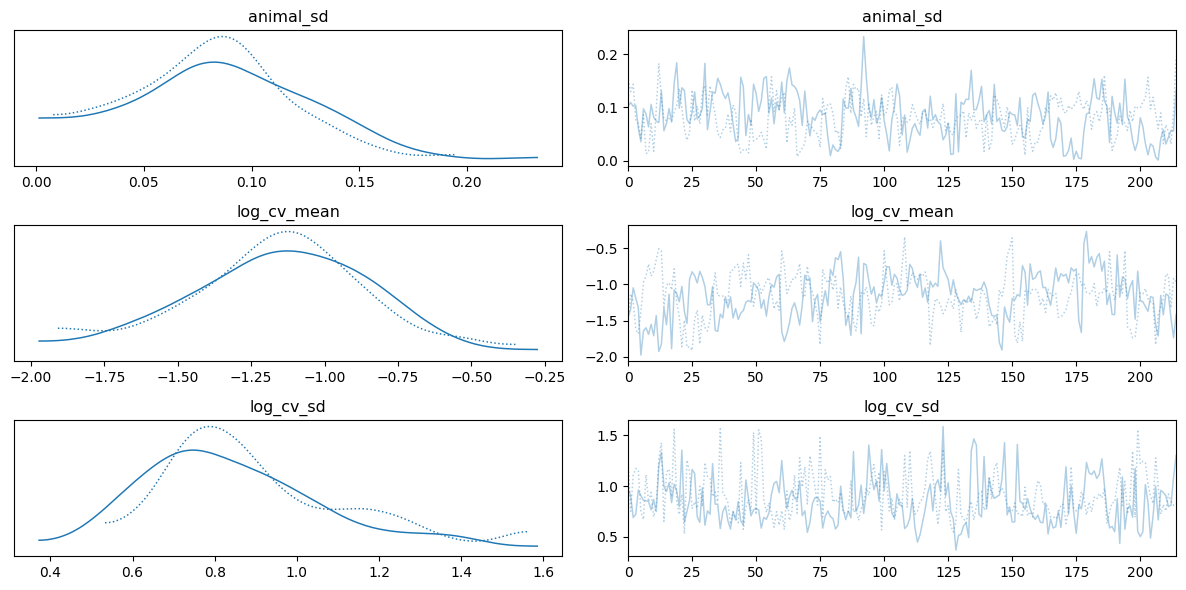

In [34]:
az.plot_trace(
    idata,
    var_names=[
        "animal_sd",
        "log_cv_mean",
        "log_cv_sd"
    ]
)

plt.tight_layout()
plt.show()


## 16.6 Generate posterior predictive datasets

A posterior predictive check asks:

> **If this fitted Bayesian model were the data-generating process, what kinds of datasets would it generate?**

For each posterior draw, PyMC generates a new replicated set of corticosterone observations.

A useful model should reproduce important features of the empirical data—not just estimate coefficients with small uncertainty.


In [35]:
with bayes_model:

    idata = pm.sample_posterior_predictive(
        idata,
        var_names=[
            "cort_obs"
        ],
        extend_inferencedata=True,
        random_seed=42
    )

posterior_predictive = (
    idata
    .posterior_predictive[
        "cort_obs"
    ]
    .stack(
        sample=(
            "chain",
            "draw"
        )
    )
    .transpose(
        "sample",
        "observation"
    )
    .values
)

posterior_predictive.shape


Sampling: [cort_obs]


/opt/homebrew/Caskroom/miniforge/base/envs/rose_gnn/lib/python3.10/site-packages/rich/live.py:260: UserWarning: 
install "ipywidgets" for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

(430, 80)

## 16.7 Smooth posterior predictive density check

The empirical density is plotted against smooth densities generated from posterior predictive datasets.

The faint curves show individual posterior predictive datasets. The shaded region summarizes the central 90% of the predictive densities at each point on the x-axis.


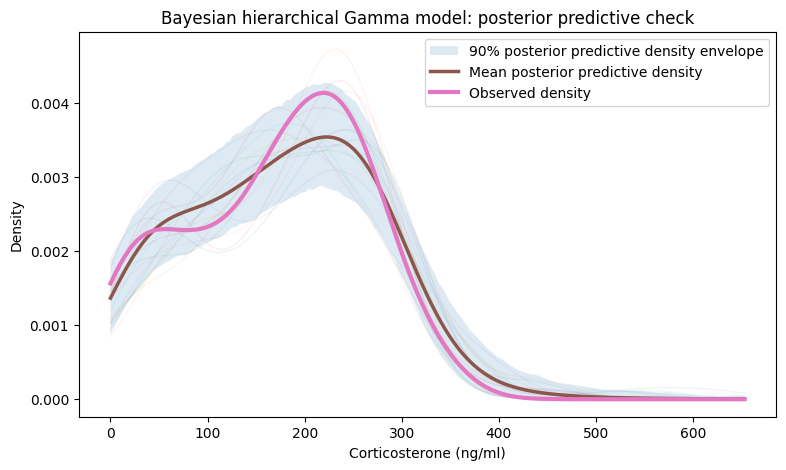

In [36]:
rng_bayes_density = np.random.default_rng(
    42
)

bayes_draw_ids = rng_bayes_density.choice(
    posterior_predictive.shape[0],
    size=min(
        500,
        posterior_predictive.shape[0]
    ),
    replace=False
)

bayesian_replicates = posterior_predictive[
    bayes_draw_ids
]

bayes_plot_high = max(
    observed.max(),
    np.quantile(
        bayesian_replicates,
        0.999
    )
)

x_grid_bayes = np.linspace(
    0,
    bayes_plot_high * 1.05,
    450
)

observed_density_bayes = gaussian_kde(
    observed
)(
    x_grid_bayes
)

bayes_density_matrix = np.asarray([
    gaussian_kde(
        replicate
    )(
        x_grid_bayes
    )
    for replicate in bayesian_replicates
])

bayes_density_low = np.quantile(
    bayes_density_matrix,
    0.05,
    axis=0
)

bayes_density_high = np.quantile(
    bayes_density_matrix,
    0.95,
    axis=0
)

fig, ax = plt.subplots(
    figsize=(
        9,
        5
    )
)

curve_ids = rng_bayes_density.choice(
    bayes_density_matrix.shape[0],
    size=min(
        15,
        bayes_density_matrix.shape[0]
    ),
    replace=False
)

for curve_id in curve_ids:
    ax.plot(
        x_grid_bayes,
        bayes_density_matrix[
            curve_id
        ],
        alpha=0.08,
        linewidth=1
    )

ax.fill_between(
    x_grid_bayes,
    bayes_density_low,
    bayes_density_high,
    alpha=0.15,
    label="90% posterior predictive density envelope"
)

ax.plot(
    x_grid_bayes,
    bayes_density_matrix.mean(
        axis=0
    ),
    linewidth=2.5,
    label="Mean posterior predictive density"
)

ax.plot(
    x_grid_bayes,
    observed_density_bayes,
    linewidth=3,
    label="Observed density"
)

ax.set_xlabel(
    "Corticosterone (ng/ml)"
)

ax.set_ylabel(
    "Density"
)

ax.set_title(
    "Bayesian hierarchical Gamma model: posterior predictive check"
)

ax.legend()

plt.show()


## 16.8 Put the Gaussian and Bayesian predictive checks side by side

The two panels below use:

- the same empirical data;
- the same KDE procedure;
- the same x-axis;
- the same type of predictive envelope.

The mathematical procedures are analogous but not identical:

### Gaussian mixed model

The fitted frequentist parameters and fitted animal effects are held fixed, then new Gaussian residual errors are simulated.

### Bayesian hierarchical Gamma model

The posterior predictive distribution integrates over posterior uncertainty in the model parameters and animal effects.

The visual question is the same:

> **Which model generates datasets that resemble the observed distribution more closely?**


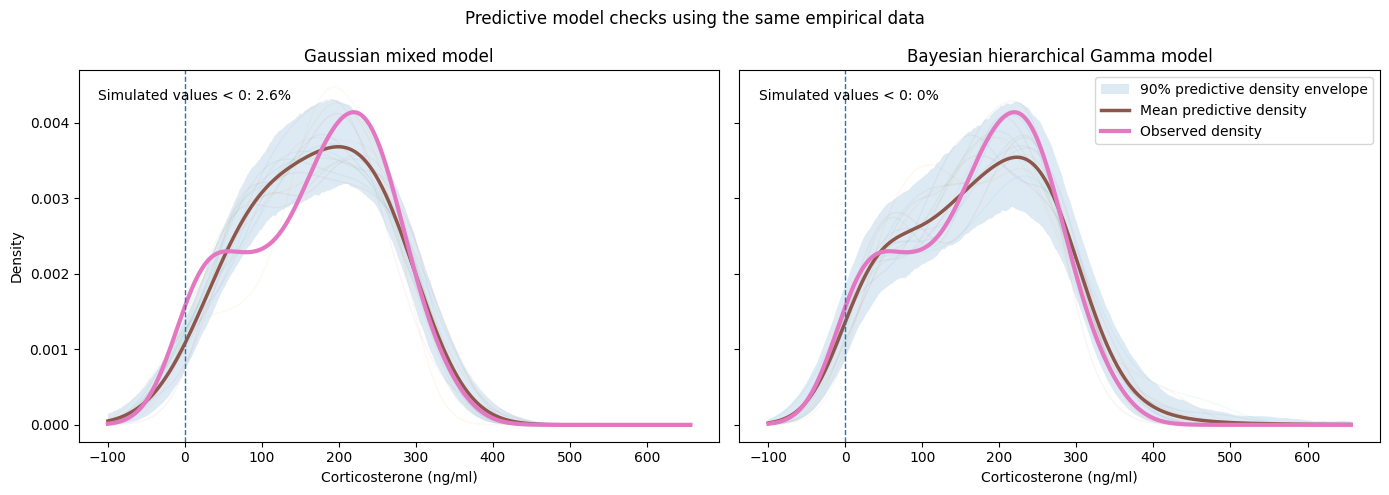

In [37]:
rng_compare = np.random.default_rng(
    42
)

bayes_compare_ids = rng_compare.choice(
    posterior_predictive.shape[0],
    size=min(
        n_density_replicates,
        posterior_predictive.shape[0]
    ),
    replace=False
)

bayesian_compare_replicates = posterior_predictive[
    bayes_compare_ids
]

combined_low = min(
    observed.min(),
    np.quantile(
        gaussian_replicates,
        0.001
    )
)

combined_high = max(
    observed.max(),
    np.quantile(
        gaussian_replicates,
        0.999
    ),
    np.quantile(
        bayesian_compare_replicates,
        0.999
    )
)

combined_padding = 0.05 * (
    combined_high -
    combined_low
)

x_grid_compare = np.linspace(
    combined_low - combined_padding,
    combined_high + combined_padding,
    500
)

observed_density_compare = gaussian_kde(
    observed
)(
    x_grid_compare
)


def kde_matrix(
    replicated_data,
    x_grid
):
    return np.asarray([
        gaussian_kde(
            replicate
        )(
            x_grid
        )
        for replicate in replicated_data
    ])


freq_density_compare = kde_matrix(
    gaussian_replicates,
    x_grid_compare
)

bayes_density_compare = kde_matrix(
    bayesian_compare_replicates,
    x_grid_compare
)

freq_low = np.quantile(
    freq_density_compare,
    0.05,
    axis=0
)

freq_high = np.quantile(
    freq_density_compare,
    0.95,
    axis=0
)

bayes_low = np.quantile(
    bayes_density_compare,
    0.05,
    axis=0
)

bayes_high = np.quantile(
    bayes_density_compare,
    0.95,
    axis=0
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(
        14,
        5
    ),
    sharex=True,
    sharey=True
)

panels = [
    (
        axes[0],
        freq_density_compare,
        freq_low,
        freq_high,
        "Gaussian mixed model"
    ),
    (
        axes[1],
        bayes_density_compare,
        bayes_low,
        bayes_high,
        "Bayesian hierarchical Gamma model"
    )
]

for (
    ax,
    density_matrix,
    envelope_low,
    envelope_high,
    title
) in panels:

    curve_ids = rng_compare.choice(
        density_matrix.shape[0],
        size=min(
            15,
            density_matrix.shape[0]
        ),
        replace=False
    )

    for curve_id in curve_ids:
        ax.plot(
            x_grid_compare,
            density_matrix[
                curve_id
            ],
            alpha=0.06,
            linewidth=1
        )

    ax.fill_between(
        x_grid_compare,
        envelope_low,
        envelope_high,
        alpha=0.15,
        label="90% predictive density envelope"
    )

    ax.plot(
        x_grid_compare,
        density_matrix.mean(
            axis=0
        ),
        linewidth=2.5,
        label="Mean predictive density"
    )

    ax.plot(
        x_grid_compare,
        observed_density_compare,
        linewidth=3,
        label="Observed density"
    )

    ax.axvline(
        0,
        linestyle="--",
        linewidth=1
    )

    ax.set_title(
        title
    )

    ax.set_xlabel(
        "Corticosterone (ng/ml)"
    )

axes[0].set_ylabel(
    "Density"
)

axes[0].text(
    0.03,
    0.95,
    (
        "Simulated values < 0: "
        f"{gaussian_negative_fraction:.1%}"
    ),
    transform=axes[0].transAxes,
    va="top"
)

axes[1].text(
    0.03,
    0.95,
    "Simulated values < 0: 0%",
    transform=axes[1].transAxes,
    va="top"
)

axes[1].legend(
    loc="best"
)

fig.suptitle(
    "Predictive model checks using the same empirical data"
)

plt.tight_layout()
plt.show()


### What to look for in the side-by-side figure

Do not judge fit only by which mean curve visually overlaps the observed density.

Ask:

1. Does the model reproduce the location of the empirical distribution?
2. Does it reproduce the width?
3. Does it reproduce the low-value shoulder and right tail?
4. Are the empirical data typical of the predictive envelope?
5. Does the model assign probability to impossible negative concentrations?

The goal is not to prove that one inferential philosophy is superior. The goal is to determine whether the chosen **data-generating model** adequately represents the measurements.


## 16.9 Check fit within each experimental condition

An overall density can look good even if the model fits particular experimental cells poorly.

The experiment contains eight group × time cells.

Because each cell contains only 8 or 12 animals, estimating a smooth empirical KDE separately in every cell can be unstable. Instead, compare:

- the observed individual animals;
- the Gaussian predictive interval;
- the Bayesian Gamma posterior predictive interval.

This directly evaluates the heteroskedastic structure that motivated the Bayesian variance model.


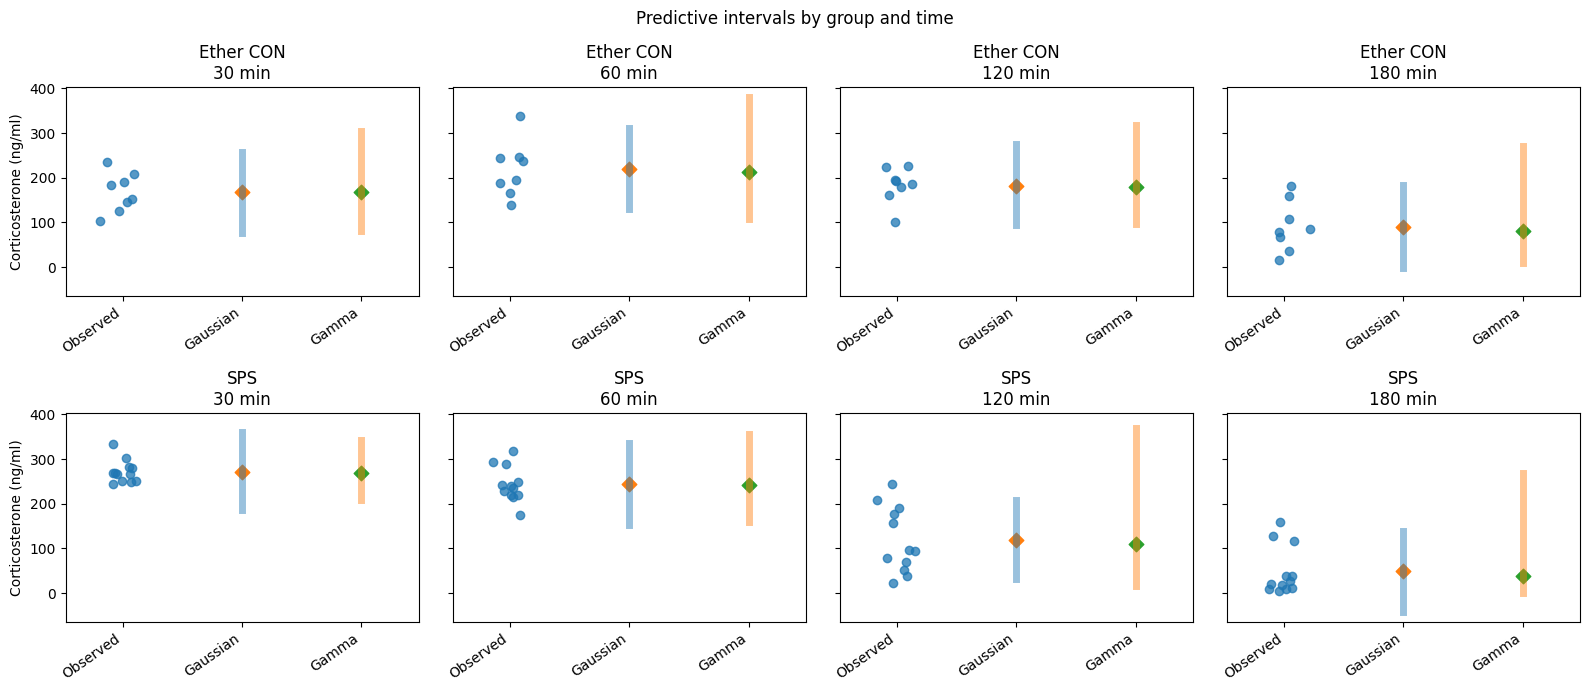

In [38]:
fig, axes = plt.subplots(
    2,
    4,
    figsize=(
        16,
        7
    ),
    sharey=True
)

groups = [
    "Ether CON",
    "SPS"
]

times = [
    30,
    60,
    120,
    180
]

rng_cell_ppc = np.random.default_rng(
    42
)

for row, group_name in enumerate(
    groups
):

    for col, time_min in enumerate(
        times
    ):

        ax = axes[
            row,
            col
        ]

        mask = (
            (
                elisa[
                    "group"
                ] == group_name
            )
            &
            (
                elisa[
                    "time_min"
                ] == time_min
            )
        ).to_numpy()

        observed_cell = observed[
            mask
        ]

        gaussian_cell = gaussian_replicates[
            :,
            mask
        ].reshape(
            -1
        )

        bayesian_cell = posterior_predictive[
            :,
            mask
        ].reshape(
            -1
        )

        jitter = rng_cell_ppc.normal(
            loc=0,
            scale=0.025,
            size=len(
                observed_cell
            )
        )

        ax.scatter(
            jitter,
            observed_cell,
            alpha=0.75,
            label="Observed"
            if (
                row == 0
                and col == 0
            )
            else None
        )

        gaussian_interval = np.quantile(
            gaussian_cell,
            [
                0.025,
                0.5,
                0.975
            ]
        )

        bayesian_interval = np.quantile(
            bayesian_cell,
            [
                0.025,
                0.5,
                0.975
            ]
        )

        ax.plot(
            [
                0.25,
                0.25
            ],
            [
                gaussian_interval[
                    0
                ],
                gaussian_interval[
                    2
                ]
            ],
            linewidth=5,
            alpha=0.45
        )

        ax.scatter(
            0.25,
            gaussian_interval[
                1
            ],
            marker="D",
            s=55
        )

        ax.plot(
            [
                0.5,
                0.5
            ],
            [
                bayesian_interval[
                    0
                ],
                bayesian_interval[
                    2
                ]
            ],
            linewidth=5,
            alpha=0.45
        )

        ax.scatter(
            0.5,
            bayesian_interval[
                1
            ],
            marker="D",
            s=55
        )

        ax.set_xlim(
            -0.12,
            0.62
        )

        ax.set_xticks(
            [
                0,
                0.25,
                0.5
            ]
        )

        ax.set_xticklabels(
            [
                "Observed",
                "Gaussian",
                "Gamma"
            ],
            rotation=35,
            ha="right"
        )

        ax.set_title(
            (
                f"{group_name}\n"
                f"{time_min} min"
            )
        )

        if col == 0:
            ax.set_ylabel(
                "Corticosterone (ng/ml)"
            )

fig.suptitle(
    "Predictive intervals by group and time"
)

plt.tight_layout()
plt.show()


## 16.10 Quantify the predictive checks

A PPC is primarily graphical, but a compact table can help students connect the visualization to interpretable features of the data.

We will compare the observed:

- mean;
- standard deviation;
- skewness;
- minimum;
- maximum;

with the distributions of those same statistics across replicated datasets.

The goal is not to create a single "fit score." Different statistics probe different features of model adequacy.


In [39]:
def replicated_statistics(
    replicated_data
):
    return pd.DataFrame({
        "Mean": np.mean(
            replicated_data,
            axis=1
        ),
        "SD": np.std(
            replicated_data,
            axis=1,
            ddof=1
        ),
        "Skewness": stats.skew(
            replicated_data,
            axis=1
        ),
        "Minimum": np.min(
            replicated_data,
            axis=1
        ),
        "Maximum": np.max(
            replicated_data,
            axis=1
        )
    })


observed_statistics = {
    "Mean": np.mean(
        observed
    ),
    "SD": np.std(
        observed,
        ddof=1
    ),
    "Skewness": stats.skew(
        observed
    ),
    "Minimum": np.min(
        observed
    ),
    "Maximum": np.max(
        observed
    )
}

gaussian_statistics = replicated_statistics(
    gaussian_replicates
)

bayesian_statistics = replicated_statistics(
    posterior_predictive
)

predictive_check_rows = []

for statistic_name, observed_value in observed_statistics.items():

    gaussian_values = gaussian_statistics[
        statistic_name
    ]

    bayesian_values = bayesian_statistics[
        statistic_name
    ]

    predictive_check_rows.append({
        "statistic": statistic_name,
        "observed": observed_value,
        "Gaussian median": np.median(
            gaussian_values
        ),
        "Gaussian 2.5%": np.quantile(
            gaussian_values,
            0.025
        ),
        "Gaussian 97.5%": np.quantile(
            gaussian_values,
            0.975
        ),
        "Gamma median": np.median(
            bayesian_values
        ),
        "Gamma 2.5%": np.quantile(
            bayesian_values,
            0.025
        ),
        "Gamma 97.5%": np.quantile(
            bayesian_values,
            0.975
        )
    })

predictive_check_table = pd.DataFrame(
    predictive_check_rows
)

predictive_check_table


,statistic,observed,Gaussian median,Gaussian 2.5%,Gaussian 97.5%,Gamma median,Gamma 2.5%,Gamma 97.5%
0,Mean,168.528,168.798,159.139,177.581,173.178,156.734,194.607
1,SD,91.226,89.803,79.665,99.218,95.794,82.854,122.613
2,Skewness,-0.283,-0.120,-0.406,0.151,-0.037,-0.344,1.642
3,Minimum,4.959,-27.437,-90.400,11.294,2.619,0.019,18.073
4,Maximum,337.245,350.073,312.914,401.591,381.513,313.108,800.628


### Interpreting the predictive-check table

An observed statistic that lies far outside a model's predictive interval identifies a specific feature that the model has difficulty reproducing.

For example:

- a minimum below zero in Gaussian replications reflects inappropriate support;
- poor reproduction of SD suggests incorrect variance assumptions;
- poor reproduction of skewness suggests the likelihood shape is inadequate;
- poor reproduction of the maximum suggests a mismatch in the upper tail.

No single statistic determines whether a model is "correct."


## 16.11 Compare variability cell by cell

The central motivation for the hierarchical Gamma model is that variability differs strongly across group × time cells.

For each posterior predictive dataset, calculate the SD within each cell and compare it with:

- the observed cell SD;
- the constant cross-animal SD implied by the Gaussian mixed model.


In [40]:
ppc_variability_rows = []

for cell_code, cell_name in enumerate(
    cell_levels
):

    mask = (
        cell_codes ==
        cell_code
    )

    observed_sd = np.std(
        observed[
            mask
        ],
        ddof=1
    )

    replicated_sd = np.std(
        posterior_predictive[
            :,
            mask
        ],
        axis=1,
        ddof=1
    )

    ppc_variability_rows.append({
        "cell": cell_name,
        "observed_sd": observed_sd,
        "bayes_sd_median": np.median(
            replicated_sd
        ),
        "bayes_sd_low": np.quantile(
            replicated_sd,
            0.025
        ),
        "bayes_sd_high": np.quantile(
            replicated_sd,
            0.975
        )
    })

ppc_variability = pd.DataFrame(
    ppc_variability_rows
)

gaussian_expected_sd = np.sqrt(
    var_animal
    +
    var_residual
)

ppc_variability[
    "gaussian_expected_sd"
] = gaussian_expected_sd

ppc_variability


,cell,observed_sd,bayes_sd_median,bayes_sd_low,bayes_sd_high,gaussian_expected_sd
0,Ether CON | 120 min,39.823,45.082,22.775,105.338,48.584
1,Ether CON | 180 min,56.464,51.072,21.473,134.859,48.584
2,Ether CON | 30 min,44.260,45.056,20.200,109.287,48.584
3,Ether CON | 60 min,61.643,56.211,24.732,116.748,48.584
4,SPS | 120 min,72.888,74.468,33.624,189.668,48.584
5,SPS | 180 min,54.134,50.463,17.823,179.297,48.584
6,SPS | 30 min,25.663,29.093,17.036,59.756,48.584
7,SPS | 60 min,39.520,42.938,23.038,80.777,48.584


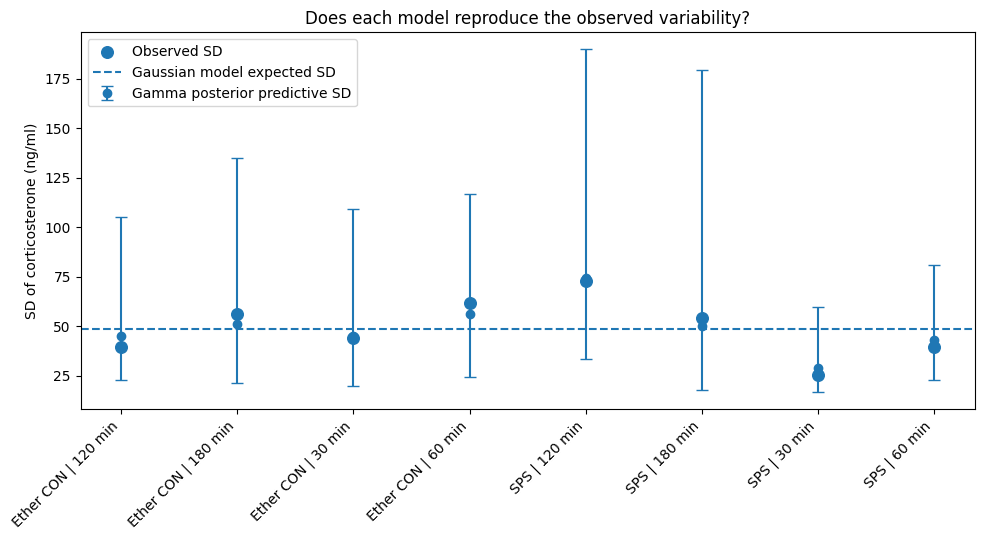

In [41]:
fig, ax = plt.subplots(
    figsize=(
        10,
        5.5
    )
)

x = np.arange(
    len(
        ppc_variability
    )
)

ax.scatter(
    x,
    ppc_variability[
        "observed_sd"
    ],
    s=70,
    label="Observed SD"
)

ax.errorbar(
    x,
    ppc_variability[
        "bayes_sd_median"
    ],
    yerr=[
        (
            ppc_variability[
                "bayes_sd_median"
            ]
            -
            ppc_variability[
                "bayes_sd_low"
            ]
        ),
        (
            ppc_variability[
                "bayes_sd_high"
            ]
            -
            ppc_variability[
                "bayes_sd_median"
            ]
        )
    ],
    fmt="o",
    capsize=4,
    label="Gamma posterior predictive SD"
)

ax.axhline(
    gaussian_expected_sd,
    linestyle="--",
    linewidth=1.5,
    label="Gaussian model expected SD"
)

ax.set_xticks(
    x
)

ax.set_xticklabels(
    ppc_variability[
        "cell"
    ],
    rotation=45,
    ha="right"
)

ax.set_ylabel(
    "SD of corticosterone (ng/ml)"
)

ax.set_title(
    "Does each model reproduce the observed variability?"
)

ax.legend()

plt.tight_layout()
plt.show()


In [42]:
gaussian_sd_error = np.sqrt(
    np.mean(
        (
            ppc_variability[
                "observed_sd"
            ]
            -
            ppc_variability[
                "gaussian_expected_sd"
            ]
        ) ** 2
    )
)

bayesian_sd_error = np.sqrt(
    np.mean(
        (
            ppc_variability[
                "observed_sd"
            ]
            -
            ppc_variability[
                "bayes_sd_median"
            ]
        ) ** 2
    )
)

variance_fit_comparison = pd.DataFrame({
    "model": [
        "Gaussian mixed model",
        "Bayesian hierarchical Gamma model"
    ],
    "RMSE_for_group_time_SD": [
        gaussian_sd_error,
        bayesian_sd_error
    ]
})

variance_fit_comparison


,model,RMSE_for_group_time_SD
0,Gaussian mixed model,13.951
1,Bayesian hierarchical Gamma model,3.973


### Interpreting the variability comparison

A smaller discrepancy means the model reproduces the observed **pattern of variability across experimental cells** more closely.

That is a specific sense in which one model may describe these data better.

It does **not** mean:

- Bayesian models always outperform frequentist models;
- the more complicated model is automatically preferable;
- a model that reproduces the observed data perfectly will necessarily generalize well to new animals.


## 16.12 Estimate population-level trajectories from the posterior

The animal random effect describes deviations of individual animals from the population trajectory.

For the Gamma model, `expected_cort` is parameterized directly as the conditional mean.

To summarize the treatment groups themselves, set the animal random effect to zero and calculate the expected population mean for each group × time combination.


In [43]:
prediction_grid = pd.DataFrame({
    "time_min": [
        30,
        60,
        120,
        180,
        30,
        60,
        120,
        180
    ],
    "group": (
        [
            "Ether CON"
        ] * 4
        +
        [
            "SPS"
        ] * 4
    )
})

grid_design = patsy.build_design_matrices(
    [
        design.design_info
    ],
    prediction_grid,
    return_type="dataframe"
)[0]

X_grid = (
    grid_design
    .iloc[
        :,
        1:
    ]
    .to_numpy()
)

posterior = idata.posterior

intercept_draws = (
    posterior[
        "intercept"
    ]
    .stack(
        sample=(
            "chain",
            "draw"
        )
    )
    .values
)

beta_draws = (
    posterior[
        "beta"
    ]
    .stack(
        sample=(
            "chain",
            "draw"
        )
    )
    .transpose(
        "sample",
        "coefficient"
    )
    .values
)

eta_grid = (
    intercept_draws[
        :,
        None
    ]
    +
    beta_draws
    @ X_grid.T
)

mean_grid_draws = np.exp(
    eta_grid
)

posterior_mean_rows = []

for i, row in prediction_grid.iterrows():

    draws = mean_grid_draws[
        :,
        i
    ]

    posterior_mean_rows.append({
        "group": row[
            "group"
        ],
        "time_min": row[
            "time_min"
        ],
        "posterior_mean_median": np.median(
            draws
        ),
        "credible_low": np.quantile(
            draws,
            0.025
        ),
        "credible_high": np.quantile(
            draws,
            0.975
        )
    })

posterior_means = pd.DataFrame(
    posterior_mean_rows
)

posterior_means


,group,time_min,posterior_mean_median,credible_low,credible_high
0,Ether CON,30,173.072,144.858,209.722
1,Ether CON,60,217.992,176.265,265.163
2,Ether CON,120,182.167,150.077,228.266
3,Ether CON,180,90.470,57.215,148.545
4,SPS,30,271.254,249.269,293.194
5,SPS,60,243.436,216.593,276.482
6,SPS,120,124.599,85.668,192.867
7,SPS,180,58.219,34.144,131.181


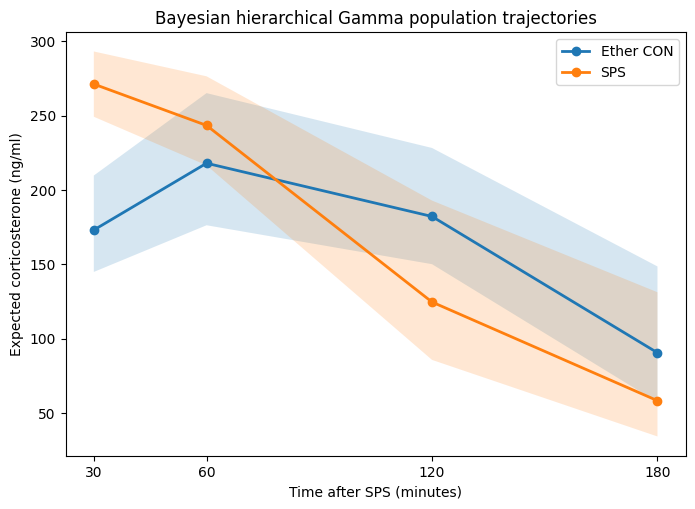

In [44]:
fig, ax = plt.subplots(
    figsize=(
        8,
        5.5
    )
)

for (
    group_name,
    group_df
) in posterior_means.groupby(
    "group"
):

    group_df = group_df.sort_values(
        "time_min"
    )

    ax.plot(
        group_df[
            "time_min"
        ],
        group_df[
            "posterior_mean_median"
        ],
        marker="o",
        linewidth=2,
        label=group_name
    )

    ax.fill_between(
        group_df[
            "time_min"
        ],
        group_df[
            "credible_low"
        ],
        group_df[
            "credible_high"
        ],
        alpha=0.18
    )

ax.set_xticks(
    [
        30,
        60,
        120,
        180
    ]
)

ax.set_xlabel(
    "Time after SPS (minutes)"
)

ax.set_ylabel(
    "Expected corticosterone (ng/ml)"
)

ax.set_title(
    "Bayesian hierarchical Gamma population trajectories"
)

ax.legend()

plt.show()


## 16.13 Bayesian group contrasts

At each time point, calculate the posterior distribution of the difference in expected corticosterone:

$$
\Delta_t
=
\mu_{\mathrm{SPS},t}
-
\mu_{\mathrm{EtherCON},t}.
$$

Report:

- posterior median difference;
- 95% credible interval;
- posterior probability that the SPS expected mean is greater than the Ether CON expected mean.


In [45]:
bayesian_contrast_rows = []

for (
    time_index,
    time_min
) in enumerate(
    [
        30,
        60,
        120,
        180
    ]
):

    control_draws = mean_grid_draws[
        :,
        time_index
    ]

    sps_draws = mean_grid_draws[
        :,
        time_index + 4
    ]

    difference_draws = (
        sps_draws
        -
        control_draws
    )

    bayesian_contrast_rows.append({
        "time_min": time_min,
        "median_difference_ng_ml": np.median(
            difference_draws
        ),
        "credible_low": np.quantile(
            difference_draws,
            0.025
        ),
        "credible_high": np.quantile(
            difference_draws,
            0.975
        ),
        "P_SPS_greater_than_control": np.mean(
            difference_draws > 0
        )
    })

bayesian_contrasts = pd.DataFrame(
    bayesian_contrast_rows
)

bayesian_contrasts


,time_min,median_difference_ng_ml,credible_low,credible_high,P_SPS_greater_than_control
0,30,97.536,59.990,131.553,1.000
1,60,27.127,-26.192,76.736,0.835
2,120,-56.148,-115.620,12.578,0.053
3,180,-30.336,-94.453,27.682,0.137


# 17. Which model should you report?

Do not choose the Bayesian model simply because it produces a preferred scientific conclusion.

Choose based on:

- measurement support;
- variance structure;
- residual and predictive diagnostics;
- sampling diagnostics;
- interpretability.

### Gaussian mixed model

Advantages:

- familiar;
- computationally fast;
- straightforward coefficients;
- convenient likelihood-ratio testing of the group × time interaction;
- useful when the Gaussian predictive distribution is adequate.

Limitations:

- permits negative concentrations;
- imposes symmetric residual error;
- uses one residual variance.

### Bayesian hierarchical Gamma model

Advantages:

- positive support;
- permits right skew;
- allows group × time-specific relative variability;
- partially pools the eight variability estimates;
- partially pools animal-specific effects;
- represents parameter uncertainty directly;
- supports posterior predictive model criticism.

Limitations:

- computationally slower;
- requires explicit priors;
- requires convergence and divergence diagnostics;
- additional flexibility must be justified by predictive behavior rather than by a preferred conclusion.

A reasonable reporting strategy is to present the Gaussian mixed model as the conventional analysis and the hierarchical Gamma model as a model-based sensitivity analysis, while showing that the conclusions are interpreted in light of the predictive checks.


## 18. Sensitivity analysis: flagged technical duplicates

A useful capstone exercise is to ask:

> **Would the scientific conclusion change if measurements with poor duplicate agreement were reviewed or excluded under a prespecified laboratory QC rule?**

We will **not** automatically perform that exclusion here.

Instead, identify the measurements flagged by the illustrative 20% rule and inspect them alongside the model residuals.


In [46]:
review_table = (
    diagnostics.loc[
        diagnostics[
            "duplicate_flag_20pct"
        ],
        [
            "animal_id",
            "group",
            "time_min",
            "plate",
            "duplicate_1",
            "duplicate_2",
            "duplicate_pct_difference",
            "cort_ng_ml",
            "residual"
        ]
    ]
    .sort_values(
        "duplicate_pct_difference",
        ascending=False
    )
)

review_table


,animal_id,group,time_min,plate,duplicate_1,duplicate_2,duplicate_pct_difference,cort_ng_ml,residual
55,A14,Ether CON,180,2,11.030,151.708,172.889,16.274,-42.063
67,A17,SPS,180,2,6.638,42.954,146.459,4.959,-38.130
71,A18,SPS,180,2,20.639,65.308,103.945,8.595,-30.425
47,A12,SPS,180,2,82.120,179.253,74.325,26.137,-19.866
34,A09,Ether CON,120,1,724.354,1226.985,51.517,195.134,21.672
11,A03,SPS,180,1,35.484,56.081,44.989,9.156,-16.897
63,A16,SPS,180,2,148.810,224.484,40.544,37.329,7.156
30,A08,Ether CON,120,1,773.793,1149.022,39.029,192.281,-4.314
59,A15,SPS,180,2,153.572,224.484,37.514,37.806,-29.399
51,A13,Ether CON,180,2,346.896,503.879,36.904,85.078,-5.706


A defensible sensitivity analysis would require an explicit rule established independently of whether removing a value improves the p-value.

Examples of defensible information might include:

- laboratory SOP;
- assay kit technical-duplicate acceptance criteria;
- evidence of pipetting failure;
- plate-reader error;
- documented sample handling problem.

The analysis should preserve a record of every exclusion and its reason.


## 19. Make the final figure

A strong final figure should show both:

- individual biological observations;
- the group-level trajectory.

Here the faint lines show individual animals, while the thicker lines and error bars show group means ± SEM.


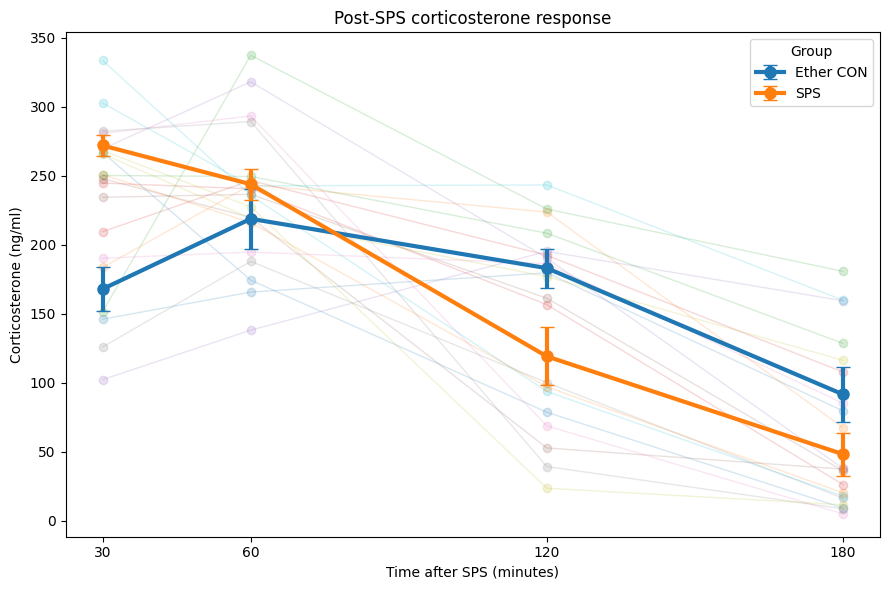

In [47]:
fig, ax = plt.subplots(
    figsize=(9, 6)
)

# Individual animals.
for (
    group_name,
    group_df
) in elisa.groupby("group"):

    for (
        animal_id,
        animal_df
    ) in group_df.groupby("animal_id"):

        animal_df = animal_df.sort_values(
            "time_min"
        )

        ax.plot(
            animal_df["time_min"],
            animal_df["cort_ng_ml"],
            marker="o",
            alpha=0.18,
            linewidth=1
        )

# Group summaries.
for (
    group_name,
    group_df
) in summary.groupby("group"):

    group_df = group_df.sort_values(
        "time_min"
    )

    ax.errorbar(
        group_df["time_min"],
        group_df["mean"],
        yerr=group_df["sem"],
        marker="o",
        markersize=8,
        linewidth=3,
        capsize=5,
        label=group_name
    )

ax.set_xticks(
    [30, 60, 120, 180]
)

ax.set_xlabel(
    "Time after SPS (minutes)"
)

ax.set_ylabel(
    "Corticosterone (ng/ml)"
)

ax.set_title(
    "Post-SPS corticosterone response"
)

ax.legend(
    title="Group"
)

plt.tight_layout()
plt.show()


## 20. Build a compact results table

For reporting, combine the descriptive statistics with the model-based group contrasts.


In [48]:
descriptive_wide = (
    summary
    .pivot(
        index="time_min",
        columns="group",
        values="mean"
    )
    .reset_index()
)

results_table = descriptive_wide.merge(
    contrasts,
    on="time_min"
)

results_table


,time_min,Ether CON,SPS,SPS_minus_EtherCON,SE,CI_low,CI_high,p_value,p_holm
0,30,167.862,271.852,103.991,22.175,60.528,147.454,2.739e-06,1.096e-05
1,60,218.728,243.772,25.043,22.175,-18.419,68.506,2.588e-01,2.588e-01
2,120,182.982,119.023,-63.959,22.175,-107.422,-20.496,3.924e-03,1.177e-02
3,180,91.499,48.160,-43.338,22.175,-86.801,0.125,5.066e-02,1.013e-01


# 21. Write the Methods

A concise Methods description should explain the analysis decisions rather than list every line of Python.

A reasonable structure is:

> Corticosterone concentrations were reconstructed from technical duplicate measurements on three ELISA plates. Technical duplicate agreement was inspected before statistical analysis. Measurements were organized in long format with four repeated time points (30, 60, 120, and 180 min) nested within animal. Corticosterone concentration was analyzed using a linear mixed-effects model with fixed effects of group, time treated as a categorical factor, and their interaction, and a random intercept for animal. The overall group × time interaction was evaluated by likelihood-ratio comparison with a reduced additive model. Model-based group contrasts were subsequently estimated at each time point and adjusted using the Holm procedure. Residual plots were inspected to evaluate model adequacy.

Before using this text in a manuscript, verify that it accurately reflects the laboratory's actual QC and assay procedures.

### If the Bayesian model is included

A concise description is:

> As a model-based sensitivity analysis, corticosterone was additionally analyzed using a Bayesian hierarchical Gamma model containing the same group, categorical-time, and group × time mean structure and an animal-level random intercept. The Gamma likelihood constrained predicted concentrations to positive values. Relative residual variability was allowed to differ across the eight group × time cells using partially pooled log-scale coefficients of variation. Weakly informative priors were used. Sampling adequacy was evaluated using divergences, R-hat, effective sample size, and trace plots, and model adequacy was assessed using posterior predictive checks.

Do not describe the Bayesian model as "better" simply because it gives a preferred result. State which likelihood and variance assumptions were motivated by the data and which predictive checks supported the model.


# 22. Write the Results from the model, not from the figure alone

A Results paragraph should answer the scientific question in this order:

### 1. Overall trajectory

Describe the broad temporal pattern visible in the data.

### 2. Interaction

Report whether the group × time interaction is supported.

### 3. Follow-up contrasts

If appropriate, report which time points show evidence of group differences and include:

- estimated difference;
- confidence interval;
- adjusted p-value.

### 4. Biological interpretation

State what the result means without implying causation beyond the experimental design.

A useful sentence structure is:

> Corticosterone changed across the post-SPS sampling period, and the temporal profile differed between SPS and Ether CON animals (group × time interaction: likelihood-ratio χ² = ___, df = ___, p = ___). Model-based contrasts indicated that SPS animals had [higher/lower] corticosterone at ___ min (estimated difference = ___ ng/ml, 95% CI ___ to ___, Holm-adjusted p = ___), whereas ___.

Fill these values from the model output rather than typing them from memory.


# 23. Final capstone questions

## Data provenance

1. Which workbook sheets were used to reconstruct the final dataset?
2. Why was the `Reinstatement` section excluded?
3. How was corrected corticosterone concentration verified?

## Quality control

4. What do technical duplicates measure?
5. Why are technical duplicates not independent biological replicates?
6. Which measurements would you review based on duplicate disagreement?
7. What evidence would justify excluding one?

## Experimental design

8. What is the experimental unit?
9. Which variable is between animals?
10. Which variable is repeated within animals?

## Statistical model

11. Why was time treated as categorical?
12. What does the group × time interaction test?
13. Why is a mixed-effects model preferable to four unrelated t-tests?

## Interpretation

14. What is the primary biological conclusion?
15. Which conclusions are supported by the data?
16. Which causal or mechanistic claims would go beyond the analysis?

## Reproducibility

17. Could another researcher reconstruct the analysis starting from the original workbook?
18. Which analysis decisions should be documented in a Methods section?
19. Which QC decisions would need laboratory documentation?
20. What files should be archived with the final analysis?

## Model fit and Bayesian analysis

21. What is the difference between a residual diagnostic and a predictive check?
22. Why was `line="s"` more appropriate than a literal 45-degree line for the raw residual Q-Q plot?
23. What does the frequentist simulation-based predictive check hold fixed?
24. Why are negative simulated corticosterone concentrations diagnostically informative?
25. Which features of the empirical density should a predictive model reproduce?
26. Why is an overall PPC insufficient when the experiment contains eight group × time cells?
27. Why was the Gamma likelihood attractive for this outcome?
28. Why were eight independent CV parameters potentially unstable?
29. What does partial pooling of the cell-specific CVs accomplish?
30. What does the animal-level random effect accomplish?
31. What do divergences tell us about MCMC sampling?
32. How are R-hat and effective sample size different from posterior predictive model fit?
33. Why are the frequentist predictive check and Bayesian posterior predictive check analogous but not identical?
34. Why should model choice be based on assumptions and predictive adequacy rather than the preferred scientific conclusion?


# Key idea

A complete computational analysis is not:

> open spreadsheet → run statistical test → report p-value.

It is:

> **understand the experiment → trace the data provenance → validate measurements → construct the analysis dataset → visualize the biology → choose a model that matches the design → diagnose the model → quantify uncertainty → communicate the result reproducibly.**
